# IND-SIS-01 · Arquitectura industrial · Versión complementaria (auditoría, noviembre 2026)

> **Copia complementaria** de `NB1_RISKTWIN_Arquitectura_Integracion_Delgado_Vargas_2.0.ipynb`. **El notebook original no se modifica.**

**Objetivo de esta copia:** generar los diagramas de componentes y entidad-relación consolidados, los contratos de entrada/salida con su interfaz hacia el núcleo común y un dataset industrial sintético exportable.

| Parte | Contenido | ¿Se ejecuta para la entrega? |
|---|---|---|
| **Parte C** (a continuación) | Bloque nuevo y autocontenido que cubre los ajustes de la auditoría | **Sí.** Ejecutar desde la celda C.0 hasta el final de la Parte C |
| **Parte B** | Copia del notebook original con ajustes puntuales marcados `# [AJUSTE AUDITORÍA]` | No es necesaria (referencia) |

**Cómo ejecutar:** ver `README_COMPLEMENTARIO.md` en la carpeta del proyecto. En Colab, poner `CLONAR_REPO = True` en la celda C.0 para que los datos de prueba y `COMUN/` se descarguen del repositorio.
Las salidas se guardan en `salidas_complementarias/`.

**Datos:** cada tabla indica `tipo_dato` (`real` / `derivado_real` / `sintetico` / `pendiente`). Los resultados sintéticos **no** deben presentarse como validación real.


# Parte C · Bloque complementario IND-SIS-01 (entrega mínima de la auditoría)

**Qué resuelve esta parte:**

1. **Diagrama de componentes** consolidado: fuentes SI-01/SI-02 → ETL → base integrada → API → consumidores (IND-SIS-02 y SIS-API-01), con su interfaz hacia el **núcleo común**.
2. **Diagrama entidad-relación** consolidado: figura, Mermaid y DDL SQL **ejecutado** en SQLite para comprobar que el esquema funciona.
3. **Contratos de entrada y salida** (Pydantic → JSON Schema) y su **correspondencia con el contrato común** H–E–V (`evento`, `observacion`).
4. Tabla de **tecnologías** y un **dataset industrial sintético pequeño** y exportable (CSV + JSON), validado contra los contratos y cargado en la base.

**Armonización con el núcleo común:** las zonas pasan de `Z01…Z06` a **`IND-Z01…IND-Z06`**, para que no choquen con las zonas urbanas `PER-Z##`. La severidad se mantiene en **1–4**, la misma escala de SIS-API-01 y del contrato común.
Todos los datos de esta parte son **sintéticos** (`tipo_dato = "sintetico"`).

Dependencias: `numpy`, `pandas`, `matplotlib`, `pydantic>=2`, `sqlite3` (incluido en Python).

In [1]:
# ===================== C.0 · Base común (idéntica en todos los notebooks complementarios) =====================
# Fuente de verdad: GEMELO DIGITAL/COMUN (contrato_hev_v1.json, zonas_perimetral.*). Si el repositorio no está
# disponible (p. ej. Colab sin clonar), se usa la tabla de zonas embebida más abajo, que es una copia exacta.
import json, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

SEMILLA = 42
rng_c = np.random.default_rng(SEMILLA)

CLONAR_REPO = False          # True en Google Colab para descargar COMUN/ y los datos de prueba del repositorio
URL_REPO = "https://github.com/AaronTech24/Gemelos_Digitales.git"

def buscar_raiz_repo():
    """Devuelve la carpeta 'GEMELO DIGITAL' del repositorio, o None si no se encuentra."""
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "COMUN" / "contrato_hev_v1.json").exists():
            return q
        if (q / "GEMELO DIGITAL" / "COMUN" / "contrato_hev_v1.json").exists():
            return q / "GEMELO DIGITAL"
    for q in [Path("/content/Gemelos_Digitales/GEMELO DIGITAL")]:
        if (q / "COMUN").exists():
            return q
    return None

RAIZ = buscar_raiz_repo()
if RAIZ is None and CLONAR_REPO:
    subprocess.run(["git", "clone", "--depth", "1", URL_REPO, "/content/Gemelos_Digitales"], check=False)
    RAIZ = buscar_raiz_repo()

def ruta_dato(*partes):
    """Ruta a un archivo del repositorio (relativa a 'GEMELO DIGITAL') o None si no existe."""
    if RAIZ is None:
        return None
    r = RAIZ.joinpath(*partes)
    return r if r.exists() else None

# --- Zonas comunes de la Vía Perimetral (COMUN/zonas_perimetral.csv, regla v1) ---
LAT_NORTE, LAT_SUR, N_ZONAS = -2.0730, -2.2425, 12
BUFFER_CORREDOR_M = 200
_COLS_Z = ["id_zona", "lat_max", "lat_min", "centroide_lat", "centroide_lon", "area_km2",
           "longitud_eje_km", "vel_max_osm_kmh", "carriles_osm"]
ZONAS_EMBEBIDAS = [
    ('PER-Z01', -2.073, -2.087125, -2.080262, -79.93277, 1.491, 3.88, 90, 3),
    ('PER-Z02', -2.087125, -2.10125, -2.094077, -79.947805, 0.662, 1.59, 90, 3),
    ('PER-Z03', -2.10125, -2.115375, -2.108339, -79.947903, 0.68, 2.29, 90, 3),
    ('PER-Z04', -2.115375, -2.1295, -2.122392, -79.948995, 0.713, 3.22, 60, 3),
    ('PER-Z05', -2.1295, -2.143625, -2.136494, -79.94695, 0.674, 1.62, 90, 3),
    ('PER-Z06', -2.143625, -2.15775, -2.15081, -79.94666, 0.675, 1.61, 90, 3),
    ('PER-Z07', -2.15775, -2.171875, -2.164975, -79.947666, 0.688, 1.65, 90, 3),
    ('PER-Z08', -2.171875, -2.186, -2.179743, -79.947688, 0.798, 1.92, 90, 3),
    ('PER-Z09', -2.186, -2.200125, -2.192248, -79.957006, 0.789, 1.87, 90, 3),
    ('PER-Z10', -2.200125, -2.21425, -2.207136, -79.956081, 0.664, 1.59, 90, 3),
    ('PER-Z11', -2.21425, -2.228375, -2.221591, -79.956534, 0.691, 1.65, 90, 3),
    ('PER-Z12', -2.228375, -2.2425, -2.235703, -79.933396, 2.147, 7.73, 90, 3)
]

def cargar_zonas():
    r = ruta_dato("COMUN", "zonas_perimetral.csv")
    if r is not None:
        z = pd.read_csv(r)
        z["origen_tabla"] = "COMUN/zonas_perimetral.csv"
    else:
        z = pd.DataFrame(ZONAS_EMBEBIDAS, columns=_COLS_Z)
        z["origen_tabla"] = "tabla embebida (copia de COMUN v1)"
    return z

ZONAS = cargar_zonas()
IDS_ZONA = ZONAS["id_zona"].tolist()

def asignar_zona(lat):
    """Regla común: franja de latitud (norte -> sur). Devuelve NaN fuera del rango del corredor."""
    lat = pd.Series(np.atleast_1d(lat), dtype=float)
    k = np.floor((LAT_NORTE - lat) / ((LAT_NORTE - LAT_SUR) / N_ZONAS))
    k = k.where((k >= 0) & (k < N_ZONAS))
    return k.map(lambda i: f"PER-Z{int(i) + 1:02d}" if pd.notna(i) else None).values

CORTES_NIVEL = [0.25, 0.50, 0.75]
def nivel(x):
    return pd.cut(pd.Series(x, dtype=float), [-np.inf, *CORTES_NIVEL, np.inf], right=False,
                  labels=["bajo", "medio", "alto", "critico"]).astype(str).values

# --- Cargador común de eventos reales (siniestros ATM y homicidios), con deduplicación documentada ---
_VEHICULOS = ["AUTOMOVIL", "BICICLETA", "BUS", "CAMION", "CAMIONETA", "EMERGENCIAS", "ESPECIAL", "FURGONETA",
              "MOTOCICLETA", "NO_IDENTIFICADO", "SCOOTER_ELECTRICO", "TRICIMOTO", "VEHICULO_DEPORTIVO_UTILITARIO"]

def _num(s):
    return pd.to_numeric(s.astype(str).str.replace(",", ".", regex=False), errors="coerce")

def cargar_eventos_reales():
    """Devuelve (EVENTOS, CALIDAD) en el esquema 'evento' del contrato. No inventa nada si faltan archivos.

    Regla de deduplicación ATM: la unidad es el código SINIESTROS. En el CSV filtrado, 1 080 filas son duplicados
    exactos y otras repiten el código cambiando solo columnas de vehículos; se conserva 1 fila por código y los
    vehículos se combinan con el máximo (presencia del tipo de vehículo en el siniestro).
    """
    eventos, calidad = [], []
    r_acc = ruta_dato("URB-04", "test_Data", "siniestros_via_perimetral_guayaquil.csv")
    r_hom = ruta_dato("URB-04", "test_Data", "homicidios_via_perimetral.csv")
    if r_acc is not None:
        a = pd.read_csv(r_acc, sep=";", encoding="utf-8-sig", dtype=str)
        n0 = len(a)
        dup_exactos = int(a.drop(columns=["id"]).duplicated().sum())
        for c in _VEHICULOS:
            a[c] = _num(a[c]).fillna(0)
        veh = a.groupby("SINIESTROS")[_VEHICULOS].max()
        a = a.drop_duplicates("SINIESTROS").set_index("SINIESTROS").drop(columns=_VEHICULOS).join(veh).reset_index()
        les, fal = _num(a.LESIONADOS).fillna(0).astype(int), _num(a.FALLECIDOS).fillna(0).astype(int)
        ev = pd.DataFrame({
            "id_evento": a.SINIESTROS, "riesgo": "accidentes_viales",
            "fecha_hora": pd.to_datetime(a.FECHA + " " + a.HORA, format="%d/%m/%Y %H:%M:%S", errors="coerce"),
            "lat": _num(a.LATITUD_Y), "lon": _num(a.LONGITUD_X), "subtipo": a.TIPO_DE_SINIESTRO,
            # severidad 1-4 (contrato): 4 con fallecidos · 3 con >= 3 lesionados · 2 con lesionados · 1 sin víctimas
            "severidad": np.select([fal > 0, les >= 3, les > 0], [4, 3, 2], 1),
            "lesionados": les, "fallecidos": fal, "motocicleta": a.MOTOCICLETA > 0,
            "arma_fuego": np.nan, "causa": a.CAUSA_PROBABLE, "feriado": a.FERIADO.eq("SI"),
            "via_osm_id": a.via_osm_id, "fuente": "F01 ATM", "tipo_dato": "real"})
        calidad.append({"riesgo": "accidentes_viales", "filas_csv": n0, "duplicados_exactos": dup_exactos,
                        "filas_extra_mismo_codigo": n0 - dup_exactos - len(ev), "eventos_unicos": len(ev)})
        eventos.append(ev)
    if r_hom is not None:
        h = pd.read_csv(r_hom, encoding="utf-8-sig", dtype=str)
        ev = pd.DataFrame({
            "id_evento": "HOM-" + h["id"].str.zfill(4), "riesgo": "seguridad_urbana",
            "fecha_hora": pd.to_datetime(h.fecha.str[:10] + " " + h.hora_infraccion.fillna("00:00:00"), errors="coerce"),
            "lat": _num(h.coordenada_y), "lon": _num(h.coordenada_x), "subtipo": h.tipo_muerte,
            "severidad": 4, "lesionados": 0, "fallecidos": 1, "motocicleta": np.nan,
            "arma_fuego": h.arma.str.contains("fuego", case=False, na=False), "causa": h.presunta_motivacion,
            "feriado": np.nan, "via_osm_id": h.via_osm_id, "fuente": "F02 homicidios", "tipo_dato": "real"})
        calidad.append({"riesgo": "seguridad_urbana", "filas_csv": len(h),
                        "duplicados_exactos": int(h.drop(columns=["id"]).duplicated().sum()),
                        "filas_extra_mismo_codigo": 0, "eventos_unicos": len(ev)})
        eventos.append(ev)
    if not eventos:
        return pd.DataFrame(columns=["id_evento", "riesgo", "fecha_hora", "lat", "lon", "id_zona"]), pd.DataFrame()
    E = pd.concat(eventos, ignore_index=True)
    E["id_zona"] = asignar_zona(E["lat"])
    C = pd.DataFrame(calidad).set_index("riesgo")
    C["fecha_invalida"] = E.groupby("riesgo").fecha_hora.apply(lambda s: int(s.isna().sum()))
    C["coordenada_invalida"] = E.groupby("riesgo").apply(lambda g: int(g[["lat", "lon"]].isna().any(axis=1).sum()))
    C["fuera_del_corredor"] = E.groupby("riesgo").id_zona.apply(lambda s: int(s.isna().sum()))
    C["desde"] = E.groupby("riesgo").fecha_hora.min()
    C["hasta"] = E.groupby("riesgo").fecha_hora.max()
    # Homicidios antes de 2023: <= 10 por año en la base -> cobertura incompleta; se excluyen de los indicadores.
    E["usar_en_indicadores"] = ~((E.riesgo == "seguridad_urbana") & (E.fecha_hora.dt.year < 2023))
    return E.dropna(subset=["id_zona"]).reset_index(drop=True), C.reset_index()

SALIDA_C = Path("salidas_complementarias")
SALIDA_C.mkdir(exist_ok=True)

print("Repositorio encontrado:", RAIZ if RAIZ else "NO (se usan tablas embebidas / datos sintéticos)")
print("Zonas comunes:", len(ZONAS), "|", ZONAS["origen_tabla"].iloc[0], "| salidas ->", SALIDA_C.resolve())

Repositorio encontrado: /home/claude/gemelos_digitales/GEMELO DIGITAL
Zonas comunes: 12 | COMUN/zonas_perimetral.csv | salidas -> /home/claude/gemelos_digitales/GEMELO DIGITAL/IND-SIS-01/src/salidas_complementarias


## C.1 · Diagrama de componentes y tecnologías

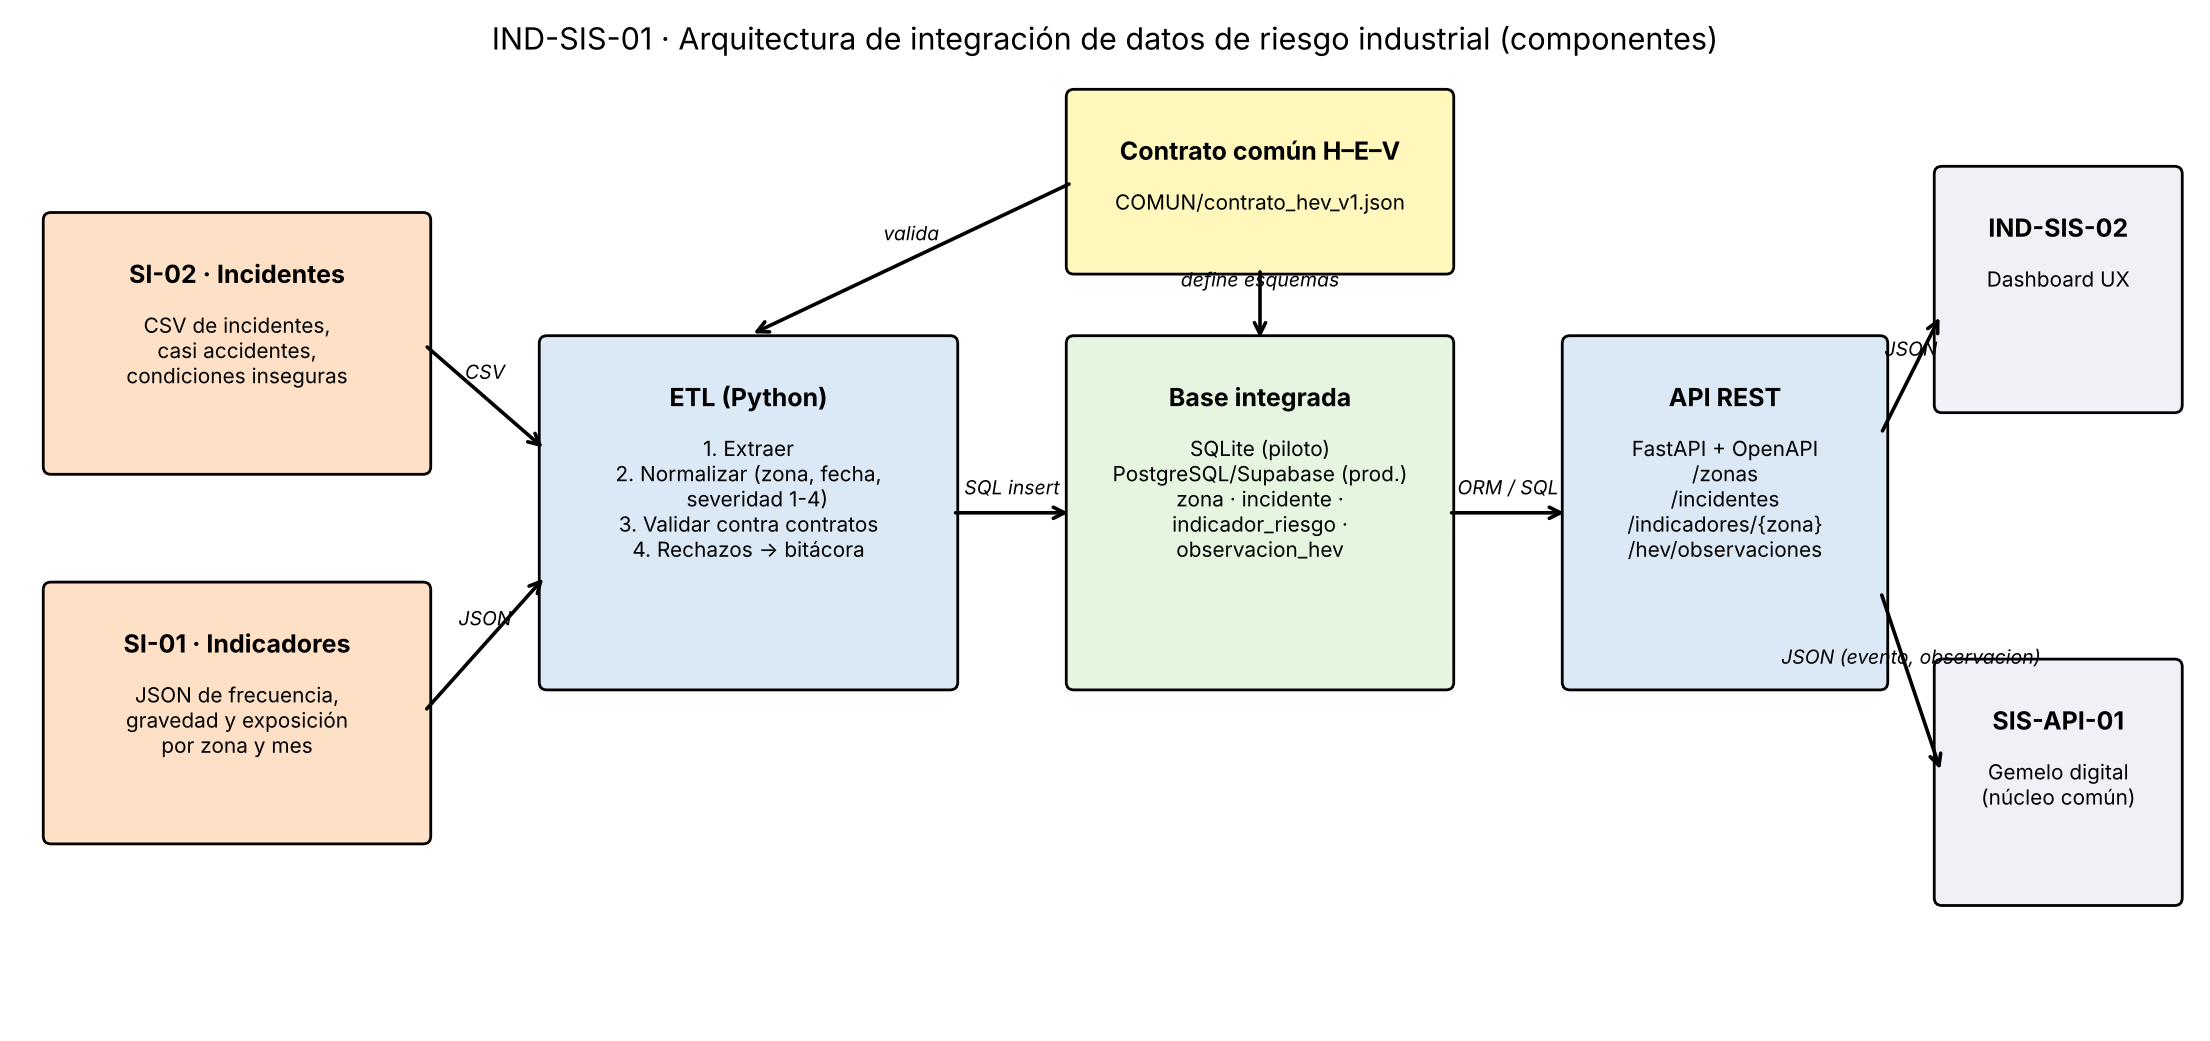

,capa,tecnologia,motivo
0,Ingesta y ETL,"Python 3.11+, pandas","Lectura CSV/JSON, normalización y bitácora de ..."
1,Contratos de datos,Pydantic 2 → JSON Schema,Una sola fuente de verdad para validación y do...
2,Base de datos,SQLite (piloto) · PostgreSQL/Supabase (producc...,Mismo DDL; claves foráneas e índices por zona ...
3,ORM,SQLAlchemy 2,Ya usado en el notebook original (Parte B)
4,API,FastAPI + Uvicorn,OpenAPI/Swagger automático; mismo stack que SI...
5,Pruebas,"pytest, TestClient",Integración y contrato
6,Consumidores,"IND-SIS-02 (Plotly), SIS-API-01",Consumen JSON según el contrato común


In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(14, 6.2)); ax.axis("off"); ax.set_xlim(0, 14); ax.set_ylim(0, 6.2)
def comp(x, y, w, h, titulo, sub, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=color, ec="k", lw=1))
    ax.text(x + w / 2, y + h - 0.25, titulo, ha="center", va="top", weight="bold", fontsize=9)
    ax.text(x + w / 2, y + h - 0.6, sub, ha="center", va="top", fontsize=7.5)
def flecha(x0, y0, x1, y1, t=""):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", lw=1.3))
    if t:
        ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.12, t, ha="center", fontsize=7, style="italic")
comp(0.2, 3.6, 2.4, 1.6, "SI-02 · Incidentes", "CSV de incidentes,\ncasi accidentes,\ncondiciones inseguras", "#fde0c5")
comp(0.2, 1.2, 2.4, 1.6, "SI-01 · Indicadores", "JSON de frecuencia,\ngravedad y exposición\npor zona y mes", "#fde0c5")
comp(3.4, 2.2, 2.6, 2.2, "ETL (Python)", "1. Extraer\n2. Normalizar (zona, fecha,\n   severidad 1-4)\n3. Validar contra contratos\n4. Rechazos -> bitácora", "#dbe9f6")
comp(6.8, 2.2, 2.4, 2.2, "Base integrada", "SQLite (piloto)\nPostgreSQL/Supabase (prod.)\nzona · incidente ·\nindicador_riesgo ·\nobservacion_hev", "#e5f5e0")
comp(10.0, 2.2, 2.0, 2.2, "API REST", "FastAPI + OpenAPI\n/zonas\n/incidentes\n/indicadores/{zona}\n/hev/observaciones", "#dbe9f6")
comp(12.4, 4.0, 1.5, 1.5, "IND-SIS-02", "Dashboard UX", "#f2f0f7")
comp(12.4, 0.8, 1.5, 1.5, "SIS-API-01", "Gemelo digital\n(núcleo común)", "#f2f0f7")
comp(6.8, 4.9, 2.4, 1.1, "Contrato común H–E–V", "COMUN/contrato_hev_v1.json", "#fff7bc")
flecha(2.6, 4.4, 3.4, 3.7, "CSV"); flecha(2.6, 2.0, 3.4, 2.9, "JSON"); flecha(6.0, 3.3, 6.8, 3.3, "SQL insert")
flecha(9.2, 3.3, 10.0, 3.3, "ORM / SQL"); flecha(12.0, 3.8, 12.4, 4.6, "JSON"); flecha(12.0, 2.8, 12.4, 1.6, "JSON (evento, observacion)")
flecha(8.0, 4.9, 8.0, 4.4, "define esquemas"); flecha(6.8, 5.45, 4.7, 4.45, "valida")
ax.set_title("IND-SIS-01 · Arquitectura de integración de datos de riesgo industrial (componentes)", fontsize=11)
plt.savefig(SALIDA_C / "indsis01_diagrama_componentes.png", dpi=140, bbox_inches="tight"); plt.show()

TECNOLOGIAS = pd.DataFrame([
    ("Ingesta y ETL", "Python 3.11+, pandas", "Lectura CSV/JSON, normalización y bitácora de rechazos"),
    ("Contratos de datos", "Pydantic 2 → JSON Schema", "Una sola fuente de verdad para validación y documentación"),
    ("Base de datos", "SQLite (piloto) · PostgreSQL/Supabase (producción)", "Mismo DDL; claves foráneas e índices por zona y fecha"),
    ("ORM", "SQLAlchemy 2", "Ya usado en el notebook original (Parte B)"),
    ("API", "FastAPI + Uvicorn", "OpenAPI/Swagger automático; mismo stack que SIS-API-01"),
    ("Pruebas", "pytest, TestClient", "Integración y contrato"),
    ("Consumidores", "IND-SIS-02 (Plotly), SIS-API-01", "Consumen JSON según el contrato común"),
], columns=["capa", "tecnologia", "motivo"])
TECNOLOGIAS.to_csv(SALIDA_C / "indsis01_tecnologias.csv", index=False, encoding="utf-8-sig")
TECNOLOGIAS

## C.2 · Modelo entidad-relación consolidado

```mermaid
erDiagram
    ZONA ||--o{ INCIDENTE : "ocurre en"
    ZONA ||--o{ INDICADOR_RIESGO : "se mide en"
    ZONA ||--o{ OBSERVACION_HEV : "describe"
    FUENTE ||--o{ INCIDENTE : "origina"
    FUENTE ||--o{ INDICADOR_RIESGO : "origina"
    ZONA {
        string id_zona PK "IND-Z##"
        string nombre
        float area_m2
    }
    INCIDENTE {
        string id_evento PK
        date fecha
        string id_zona FK
        string tipo_evento
        int severidad "1-4"
        int dias_perdidos
        string fuente_id FK
        string tipo_dato
    }
    INDICADOR_RIESGO {
        int id PK
        string id_zona FK
        string periodo "AAAA-MM"
        float indice_frecuencia
        float indice_gravedad
        float exposicion_horas
        string nivel_riesgo
        string fuente_id FK
    }
    OBSERVACION_HEV {
        int id PK
        string id_zona FK
        string periodo
        string id_variable
        string componente "H/E/V"
        float valor
        string tipo_dato
    }
    FUENTE {
        string fuente_id PK
        string nombre
        string tesis
    }
```

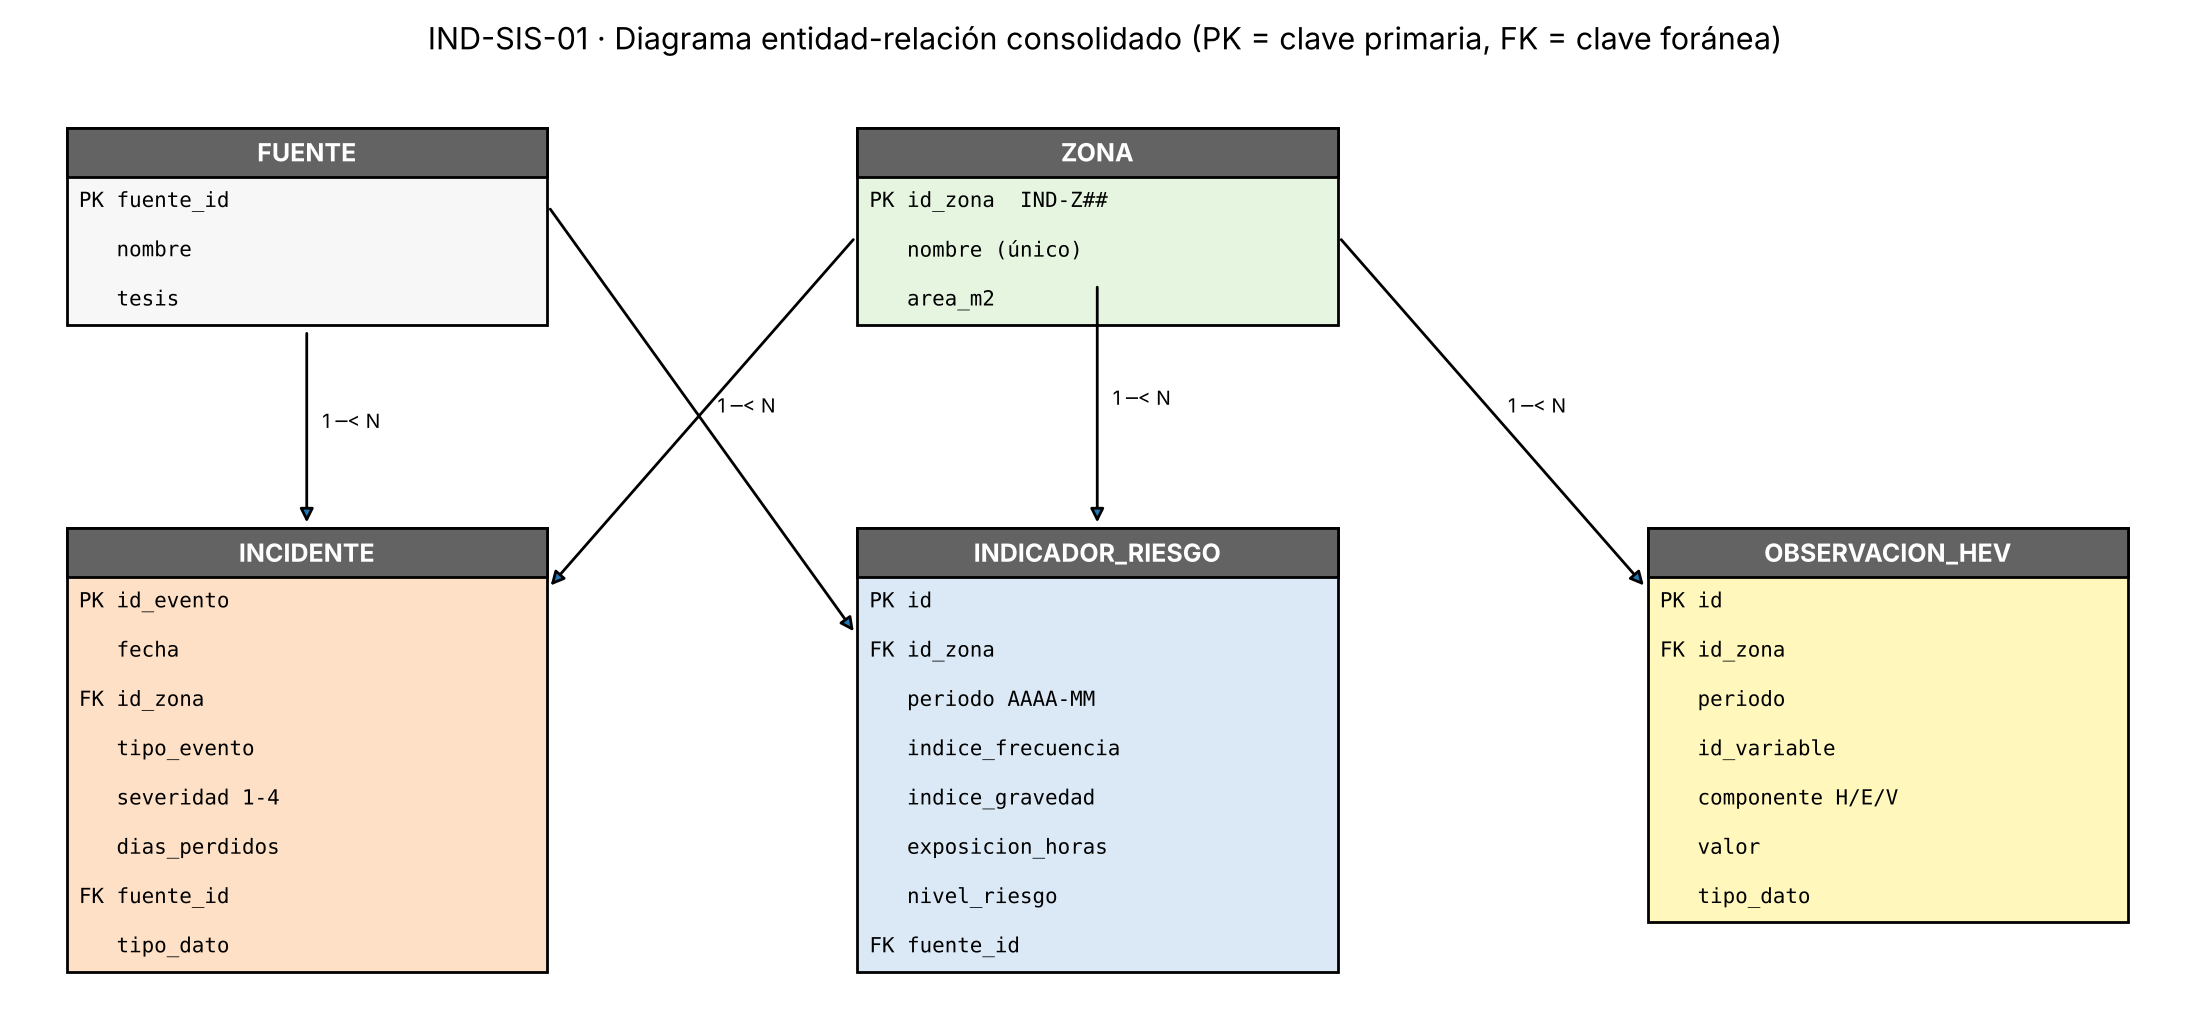

In [3]:
DDL = """
CREATE TABLE fuente (
  fuente_id   TEXT PRIMARY KEY,
  nombre      TEXT NOT NULL,
  tesis       TEXT NOT NULL
);
CREATE TABLE zona (
  id_zona     TEXT PRIMARY KEY CHECK (id_zona GLOB 'IND-Z[0-9][0-9]'),
  nombre      TEXT NOT NULL UNIQUE,
  area_m2     REAL CHECK (area_m2 > 0)
);
CREATE TABLE incidente (
  id_evento     TEXT PRIMARY KEY,
  fecha         TEXT NOT NULL,                                   -- ISO 8601
  id_zona       TEXT NOT NULL REFERENCES zona(id_zona),
  tipo_evento   TEXT NOT NULL,
  severidad     INTEGER NOT NULL CHECK (severidad BETWEEN 1 AND 4),
  dias_perdidos INTEGER CHECK (dias_perdidos >= 0),
  fuente_id     TEXT NOT NULL REFERENCES fuente(fuente_id),
  tipo_dato     TEXT NOT NULL CHECK (tipo_dato IN ('real', 'sintetico'))
);
CREATE INDEX ix_incidente_zona_fecha ON incidente(id_zona, fecha);
CREATE TABLE indicador_riesgo (
  id                INTEGER PRIMARY KEY AUTOINCREMENT,
  id_zona           TEXT NOT NULL REFERENCES zona(id_zona),
  periodo           TEXT NOT NULL,                               -- AAAA-MM
  indice_frecuencia REAL NOT NULL CHECK (indice_frecuencia >= 0),
  indice_gravedad   REAL NOT NULL CHECK (indice_gravedad >= 0),
  exposicion_horas  REAL NOT NULL CHECK (exposicion_horas > 0),
  nivel_riesgo      TEXT NOT NULL CHECK (nivel_riesgo IN ('bajo', 'medio', 'alto', 'critico')),
  fuente_id         TEXT NOT NULL REFERENCES fuente(fuente_id),
  UNIQUE (id_zona, periodo)
);
CREATE TABLE observacion_hev (
  id          INTEGER PRIMARY KEY AUTOINCREMENT,
  id_zona     TEXT NOT NULL REFERENCES zona(id_zona),
  periodo     TEXT NOT NULL,
  id_variable TEXT NOT NULL,
  componente  TEXT NOT NULL CHECK (componente IN ('H', 'E', 'V')),
  valor       REAL,
  tipo_dato   TEXT NOT NULL,
  UNIQUE (id_zona, periodo, id_variable)
);
"""
(SALIDA_C / "indsis01_esquema.sql").write_text(DDL.strip() + "\n", encoding="utf-8")

fig, ax = plt.subplots(figsize=(14, 6)); ax.axis("off"); ax.set_xlim(0, 14); ax.set_ylim(0, 6)
def entidad(x, y, titulo, cols, color):
    h = 0.32 * (len(cols) + 1)
    ax.add_patch(plt.Rectangle((x, y - h), 3.1, h, fc=color, ec="k"))
    ax.add_patch(plt.Rectangle((x, y - 0.32), 3.1, 0.32, fc="#636363", ec="k"))
    ax.text(x + 1.55, y - 0.16, titulo, color="w", ha="center", va="center", weight="bold", fontsize=9)
    for i, c in enumerate(cols):
        ax.text(x + 0.08, y - 0.48 - 0.32 * i, c, fontsize=7.5, va="center", family="monospace")
    return (x, y, h)
entidad(0.3, 5.6, "FUENTE", ["PK fuente_id", "   nombre", "   tesis"], "#f7f7f7")
entidad(5.4, 5.6, "ZONA", ["PK id_zona  IND-Z##", "   nombre (único)", "   area_m2"], "#e5f5e0")
entidad(0.3, 3.0, "INCIDENTE", ["PK id_evento", "   fecha", "FK id_zona", "   tipo_evento", "   severidad 1-4", "   dias_perdidos",
                                "FK fuente_id", "   tipo_dato"], "#fde0c5")
entidad(5.4, 3.0, "INDICADOR_RIESGO", ["PK id", "FK id_zona", "   periodo AAAA-MM", "   indice_frecuencia", "   indice_gravedad",
                                       "   exposicion_horas", "   nivel_riesgo", "FK fuente_id"], "#dbe9f6")
entidad(10.5, 3.0, "OBSERVACION_HEV", ["PK id", "FK id_zona", "   periodo", "   id_variable", "   componente H/E/V", "   valor",
                                       "   tipo_dato"], "#fff7bc")
for (x0, y0, x1, y1, t) in [(6.95, 4.6, 6.95, 3.0, "1 ─< N"), (5.4, 4.9, 3.4, 2.6, "1 ─< N"), (8.5, 4.9, 10.5, 2.6, "1 ─< N"),
                            (1.85, 4.3, 1.85, 3.0, "1 ─< N"), (3.4, 5.1, 5.4, 2.3, "")]:
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", lw=1))
    if t:
        ax.text((x0 + x1) / 2 + 0.1, (y0 + y1) / 2, t, fontsize=7)
ax.set_title("IND-SIS-01 · Diagrama entidad-relación consolidado (PK = clave primaria, FK = clave foránea)", fontsize=11)
plt.savefig(SALIDA_C / "indsis01_diagrama_entidad_relacion.png", dpi=140, bbox_inches="tight"); plt.show()

## C.3 · Contratos de entrada y salida, e interfaz con el núcleo común

In [4]:
from datetime import date
from typing import Literal, Optional
from pydantic import BaseModel, ConfigDict, Field, ValidationError

class _B(BaseModel):
    model_config = ConfigDict(extra="forbid", str_strip_whitespace=True)

class EntradaIncidenteSI02(_B):
    """Entrada: fila del CSV de SI-02 ya normalizada por el ETL."""
    id_evento: str = Field(pattern=r"^INC-\d{4,}$")
    fecha: date
    id_zona: str = Field(pattern=r"^IND-Z\d{2}$")
    tipo_evento: Literal["Caída", "Golpe", "Quemadura", "Exposición química", "Atrapamiento", "Corte"]
    severidad: int = Field(ge=1, le=4)
    dias_perdidos: int = Field(ge=0)
    tipo_dato: Literal["real", "sintetico"]

class EntradaIndicadorSI01(_B):
    """Entrada: registro del JSON de SI-01, aplanado."""
    id_zona: str = Field(pattern=r"^IND-Z\d{2}$")
    periodo: str = Field(pattern=r"^\d{4}-\d{2}$")
    indice_frecuencia: float = Field(ge=0)
    indice_gravedad: float = Field(ge=0)
    exposicion_horas: float = Field(gt=0)
    nivel_riesgo: Literal["bajo", "medio", "alto", "critico"]

class SalidaIndicadoresZona(_B):
    """Salida de GET /indicadores/{id_zona}: lo que consume IND-SIS-02."""
    id_zona: str
    nombre: str
    periodo_desde: str
    periodo_hasta: str
    n_incidentes: int
    severidad_media: float = Field(ge=1, le=4)
    indice_frecuencia_medio: float
    indice_gravedad_medio: float
    nivel_mas_reciente: Literal["bajo", "medio", "alto", "critico"]

class SalidaEventoComun(_B):
    """Salida hacia SIS-API-01: incidente traducido a 'evento' del contrato común."""
    id_evento: str
    riesgo: Literal["industrial"] = "industrial"
    id_zona: str
    fecha_hora: str
    subtipo: str
    severidad: int = Field(ge=1, le=4)
    lesionados: int = 0
    fallecidos: int = 0
    fuente: str
    tipo_dato: Literal["real", "sintetico"]

CONTRATOS = {m.__name__: m.model_json_schema() for m in [EntradaIncidenteSI02, EntradaIndicadorSI01, SalidaIndicadoresZona, SalidaEventoComun]}
(SALIDA_C / "indsis01_contratos_entrada_salida.schema.json").write_text(json.dumps(CONTRATOS, ensure_ascii=False, indent=1), encoding="utf-8")

MAPEO = pd.DataFrame([
    ("INCIDENTE.id_evento", "evento.id_evento", "igual"),
    ("—", "evento.riesgo", "constante 'industrial'"),
    ("INCIDENTE.id_zona (IND-Z##)", "evento.id_zona", "igual; patrón ^(PER|IND)-Z\\d{2}$"),
    ("INCIDENTE.fecha", "evento.fecha_hora", "fecha + 'T00:00:00' (SI-02 no registra hora)"),
    ("INCIDENTE.tipo_evento", "evento.subtipo", "igual"),
    ("INCIDENTE.severidad (1-4)", "evento.severidad (1-4)", "igual (misma escala)"),
    ("INCIDENTE.severidad = 4", "evento.fallecidos", "SI-02 no informa fallecidos: queda 0 y se documenta"),
    ("INCIDENTE.tipo_dato", "evento.tipo_dato", "igual"),
    ("INDICADOR_RIESGO.indice_frecuencia", "observacion(id_variable='IND_H_indice_frecuencia', componente='H')", "peligrosidad"),
    ("INDICADOR_RIESGO.exposicion_horas", "observacion(id_variable='IND_E_exposicion_horas', componente='E')", "exposición"),
    ("INDICADOR_RIESGO.indice_gravedad", "observacion(id_variable='IND_V_indice_gravedad', componente='V')", "proxy de vulnerabilidad (daño por evento)"),
], columns=["origen IND-SIS-01", "destino contrato común", "regla"])
MAPEO.to_csv(SALIDA_C / "indsis01_interfaz_nucleo_comun.csv", index=False, encoding="utf-8-sig")
print("Contratos exportados:", list(CONTRATOS))
MAPEO

Contratos exportados: ['EntradaIncidenteSI02', 'EntradaIndicadorSI01', 'SalidaIndicadoresZona', 'SalidaEventoComun']


,origen IND-SIS-01,destino contrato común,regla
0,INCIDENTE.id_evento,evento.id_evento,igual
1,—,evento.riesgo,constante 'industrial'
2,INCIDENTE.id_zona (IND-Z##),evento.id_zona,igual; patrón ^(PER|IND)-Z\d{2}$
3,INCIDENTE.fecha,evento.fecha_hora,fecha + 'T00:00:00' (SI-02 no registra hora)
4,INCIDENTE.tipo_evento,evento.subtipo,igual
5,INCIDENTE.severidad (1-4),evento.severidad (1-4),igual (misma escala)
6,INCIDENTE.severidad = 4,evento.fallecidos,SI-02 no informa fallecidos: queda 0 y se docu...
7,INCIDENTE.tipo_dato,evento.tipo_dato,igual
8,INDICADOR_RIESGO.indice_frecuencia,observacion(id_variable='IND_H_indice_frecuenc...,peligrosidad
9,INDICADOR_RIESGO.exposicion_horas,observacion(id_variable='IND_E_exposicion_hora...,exposición


## C.4 · Dataset industrial sintético pequeño (exportable)

In [5]:
ZONAS_IND = pd.DataFrame([("IND-Z01", "Caldera", 900), ("IND-Z02", "Almacén de químicos", 650), ("IND-Z03", "Línea de ensamblaje", 1800),
                          ("IND-Z04", "Soldadura", 700), ("IND-Z05", "Bodega general", 1500), ("IND-Z06", "Carga y descarga", 1100)],
                         columns=["id_zona", "nombre", "area_m2"])
r = np.random.default_rng(SEMILLA)
TIPOS = ["Caída", "Golpe", "Quemadura", "Exposición química", "Atrapamiento", "Corte"]
p_zona = np.array([0.25, 0.20, 0.10, 0.20, 0.10, 0.15])
dias = pd.date_range("2026-01-01", "2026-08-31")
inc = []
for i in range(120):
    z = str(r.choice(ZONAS_IND.id_zona.values, p=p_zona))
    sev = int(r.choice([1, 2, 3, 4], p=[0.45, 0.30, 0.18, 0.07]))
    inc.append({"id_evento": f"INC-{i + 1:04d}", "fecha": str(dias[r.integers(len(dias))].date()), "id_zona": z, "tipo_evento": str(r.choice(TIPOS)),
                "severidad": sev, "dias_perdidos": int({1: 0, 2: r.integers(1, 4), 3: r.integers(4, 16), 4: r.integers(16, 61)}[sev]),
                "tipo_dato": "sintetico"})
INCIDENTES = pd.DataFrame(inc).sort_values("fecha").reset_index(drop=True)

ind = []
base_f = dict(zip(ZONAS_IND.id_zona, [12, 9, 5, 11, 4, 7])); base_g = dict(zip(ZONAS_IND.id_zona, [30, 42, 10, 28, 8, 15]))
for z in ZONAS_IND.id_zona:
    for m in range(1, 9):
        f_, g_ = max(0.5, r.normal(base_f[z], 1.5)), max(1.0, r.normal(base_g[z], 4))
        p_ = f_ * g_ / 20
        ind.append({"id_zona": z, "periodo": f"2026-{m:02d}", "indice_frecuencia": round(f_, 2), "indice_gravedad": round(g_, 2),
                    "exposicion_horas": float(r.integers(1800, 5200)),
                    "nivel_riesgo": "bajo" if p_ < 8 else "medio" if p_ < 18 else "alto" if p_ < 30 else "critico"})
INDICADORES = pd.DataFrame(ind)

# Validación contra los contratos de entrada (si algo falla, se detiene)
errores = []
for i, row in INCIDENTES.iterrows():
    try: EntradaIncidenteSI02(**row.to_dict())
    except ValidationError as e: errores.append(("incidente", i, str(e)))
for i, row in INDICADORES.iterrows():
    try: EntradaIndicadorSI01(**row.to_dict())
    except ValidationError as e: errores.append(("indicador", i, str(e)))
print(f"Incidentes: {len(INCIDENTES)} · indicadores: {len(INDICADORES)} · errores de contrato: {len(errores)}")
assert not errores

INCIDENTES.to_csv(SALIDA_C / "indsis01_dataset_incidentes_sintetico.csv", index=False, encoding="utf-8-sig")
INDICADORES.to_csv(SALIDA_C / "indsis01_dataset_indicadores_sintetico.csv", index=False, encoding="utf-8-sig")
ZONAS_IND.to_csv(SALIDA_C / "indsis01_dataset_zonas.csv", index=False, encoding="utf-8-sig")
(SALIDA_C / "indsis01_dataset_sintetico.json").write_text(json.dumps(
    {"version_contrato": "1.0.0", "tipo_dato": "sintetico", "semilla": SEMILLA, "zonas": ZONAS_IND.to_dict("records"),
     "incidentes": INCIDENTES.to_dict("records"), "indicadores": INDICADORES.to_dict("records")}, ensure_ascii=False, indent=1), encoding="utf-8")
display(INCIDENTES.head())

Incidentes: 120 · indicadores: 48 · errores de contrato: 0


,id_evento,fecha,id_zona,tipo_evento,severidad,dias_perdidos,tipo_dato
0,INC-0079,2026-01-02,IND-Z01,Exposición química,2,2,sintetico
1,INC-0054,2026-01-05,IND-Z01,Golpe,3,9,sintetico
2,INC-0040,2026-01-11,IND-Z02,Caída,4,49,sintetico
3,INC-0099,2026-01-13,IND-Z01,Golpe,2,1,sintetico
4,INC-0032,2026-01-21,IND-Z03,Quemadura,2,3,sintetico


## C.5 · Carga en la base y consultas de comprobación (el ER funciona)

In [6]:
import sqlite3
DB = SALIDA_C / "indsis01_piloto.db"
if DB.exists():
    DB.unlink()
con = sqlite3.connect(DB); con.execute("PRAGMA foreign_keys = ON"); con.executescript(DDL)
con.executemany("INSERT INTO fuente VALUES (?,?,?)", [("F-SI02", "Incidentes SI-02", "SI-02"), ("F-SI01", "Indicadores SI-01", "SI-01")])
con.executemany("INSERT INTO zona VALUES (?,?,?)", ZONAS_IND.itertuples(index=False))
con.executemany("INSERT INTO incidente VALUES (?,?,?,?,?,?,?,?)",
                [(*t[:6], "F-SI02", t[6]) for t in INCIDENTES[["id_evento", "fecha", "id_zona", "tipo_evento", "severidad", "dias_perdidos", "tipo_dato"]].itertuples(index=False)])
con.executemany("INSERT INTO indicador_riesgo (id_zona, periodo, indice_frecuencia, indice_gravedad, exposicion_horas, nivel_riesgo, fuente_id) VALUES (?,?,?,?,?,?,?)",
                [(*t, "F-SI01") for t in INDICADORES.itertuples(index=False)])
obs = [(t.id_zona, t.periodo, v, c, float(getattr(t, col)), "sintetico") for t in INDICADORES.itertuples()
       for v, c, col in [("IND_H_indice_frecuencia", "H", "indice_frecuencia"), ("IND_E_exposicion_horas", "E", "exposicion_horas"),
                         ("IND_V_indice_gravedad", "V", "indice_gravedad")]]
con.executemany("INSERT INTO observacion_hev (id_zona, periodo, id_variable, componente, valor, tipo_dato) VALUES (?,?,?,?,?,?)", obs)
con.commit()

# Pruebas de integridad: las restricciones deben rechazar datos inválidos
rechazos = {}
for nombre, sql, args in [("zona fuera de catálogo", "INSERT INTO incidente VALUES (?,?,?,?,?,?,?,?)", ("INC-9999", "2026-01-01", "IND-Z99", "Caída", 2, 0, "F-SI02", "sintetico")),
                          ("severidad 5 (escala antigua)", "INSERT INTO incidente VALUES (?,?,?,?,?,?,?,?)", ("INC-9998", "2026-01-01", "IND-Z01", "Caída", 5, 0, "F-SI02", "sintetico")),
                          ("código de zona antiguo Z01", "INSERT INTO zona VALUES (?,?,?)", ("Z01", "Otra", 10)),
                          ("periodo duplicado", "INSERT INTO indicador_riesgo (id_zona, periodo, indice_frecuencia, indice_gravedad, exposicion_horas, nivel_riesgo, fuente_id) VALUES (?,?,?,?,?,?,?)",
                           ("IND-Z01", "2026-01", 1, 1, 100, "bajo", "F-SI01"))]:
    try:
        con.execute(sql, args); rechazos[nombre] = "ACEPTADO (error)"
    except sqlite3.IntegrityError:
        rechazos[nombre] = "rechazado ✔"
con.rollback()
display(pd.DataFrame({"prueba de integridad": list(rechazos), "resultado": list(rechazos.values())}))

SALIDA_API = pd.read_sql("""
SELECT z.id_zona, z.nombre, MIN(i.periodo) AS periodo_desde, MAX(i.periodo) AS periodo_hasta,
       (SELECT COUNT(*) FROM incidente x WHERE x.id_zona = z.id_zona) AS n_incidentes,
       ROUND((SELECT AVG(severidad) FROM incidente x WHERE x.id_zona = z.id_zona), 2) AS severidad_media,
       ROUND(AVG(i.indice_frecuencia), 2) AS indice_frecuencia_medio, ROUND(AVG(i.indice_gravedad), 2) AS indice_gravedad_medio,
       (SELECT nivel_riesgo FROM indicador_riesgo y WHERE y.id_zona = z.id_zona ORDER BY periodo DESC LIMIT 1) AS nivel_mas_reciente
FROM zona z JOIN indicador_riesgo i ON i.id_zona = z.id_zona GROUP BY z.id_zona ORDER BY z.id_zona""", con)
for row in SALIDA_API.to_dict("records"):
    SalidaIndicadoresZona(**row)                      # la consulta cumple el contrato de salida
eventos_comunes = [SalidaEventoComun(id_evento=t.id_evento, id_zona=t.id_zona, fecha_hora=f"{t.fecha}T00:00:00", subtipo=t.tipo_evento,
                                     severidad=t.severidad, fuente="F-SI02", tipo_dato=t.tipo_dato).model_dump()
                   for t in INCIDENTES.head(3).itertuples()]
(SALIDA_C / "indsis01_ejemplo_salida_api.json").write_text(json.dumps({"GET /indicadores": SALIDA_API.to_dict("records"),
                                                                        "eventos_contrato_comun": eventos_comunes}, ensure_ascii=False, indent=1), encoding="utf-8")
con.close()
print("Salida de GET /indicadores (validada contra SalidaIndicadoresZona):")
display(SALIDA_API)
assert all(v == "rechazado ✔" for v in rechazos.values())

,prueba de integridad,resultado
0,zona fuera de catálogo,rechazado ✔
1,severidad 5 (escala antigua),rechazado ✔
2,código de zona antiguo Z01,rechazado ✔
3,periodo duplicado,rechazado ✔


Salida de GET /indicadores (validada contra SalidaIndicadoresZona):


,id_zona,nombre,periodo_desde,periodo_hasta,n_incidentes,severidad_media,indice_frecuencia_medio,indice_gravedad_medio,nivel_mas_reciente
0,IND-Z01,Caldera,2026-01,2026-08,35,1.94,12.97,28.49,medio
1,IND-Z02,Almacén de químicos,2026-01,2026-08,17,1.82,8.63,41.77,medio
2,IND-Z03,Línea de ensamblaje,2026-01,2026-08,15,1.47,5.24,8.20,bajo
3,IND-Z04,Soldadura,2026-01,2026-08,21,1.76,11.55,25.85,medio
4,IND-Z05,Bodega general,2026-01,2026-08,13,1.77,3.60,6.13,bajo
5,IND-Z06,Carga y descarga,2026-01,2026-08,19,2.05,6.87,13.67,bajo


## C.6 · Entregables y limitaciones

| Entregable mínimo (auditoría) | Archivo en `salidas_complementarias/` |
|---|---|
| Diagrama de arquitectura | `indsis01_diagrama_componentes.png` |
| Entidad-relación | `indsis01_diagrama_entidad_relacion.png`, diagrama Mermaid (C.2), `indsis01_esquema.sql` |
| Contratos | `indsis01_contratos_entrada_salida.schema.json`, `indsis01_interfaz_nucleo_comun.csv`, `indsis01_ejemplo_salida_api.json` |
| Tecnologías | `indsis01_tecnologias.csv` |
| Dataset de prueba | `indsis01_dataset_*.csv`, `indsis01_dataset_sintetico.json`, `indsis01_piloto.db` |

**Limitaciones:**
* El dataset es sintético: no representa una planta real. Los registros "sucios" del notebook original (Parte B) siguen siendo útiles para probar el ETL.
* SI-01 y SI-02 todavía no entregan datos reales (sus carpetas en el repositorio solo tienen marcadores). Los contratos de entrada son la propuesta que deben confirmar esos equipos.
* `indice_gravedad` se usa como **proxy** de vulnerabilidad. SI-01 debe confirmar o reemplazar esta asignación H–E–V.

---
# Parte B · Notebook original (referencia)

Las celdas siguientes son una **copia del notebook original `NB1_RISKTWIN_Arquitectura_Integracion_Delgado_Vargas_2.0.ipynb`**. Se conservan para que el equipo
pueda comparar y reutilizar código, pero **no forman parte de la entrega mínima**: la entrega es la Parte C
(arriba). Las celdas de esta parte requieren las mismas dependencias y credenciales que el original
(OSM/Overpass, Supabase, API de LLM, etc.).

**Ajustes puntuales aplicados en esta copia** (marcados en el código con `# [AJUSTE AUDITORÍA]`):

* Catálogo de zonas: nota de equivalencia `Z0# → IND-Z0#` según el contrato común. El código original no se cambió, para no romper la Parte B.


# 🛡️ RISKTWIN · Piloto de la arquitectura de integración de datos de riesgo industrial

**Notebook piloto (prueba de concepto) en Google Colab**

**Tema de tesis:** *Arquitectura de software para la integración de datos fragmentados de riesgo industrial en un gemelo digital multimodal*
**Autores:** Delgado Quiñonez Elian Adonis · Vargas Ordoñez Stalyn Gabriel
**Institución:** Universidad de Guayaquil · Facultad de Ingeniería Industrial · Sistemas de la Información

---

## ¿Qué demuestra este notebook?

En RISKTWIN, los componentes **SI-01** (indicadores de riesgo) y **SI-02** (dataset de incidentes) se desarrollan por separado y **no comparten un modelo de datos común**. Este notebook construye, en pequeño y de punta a punta, la **capa de integración** que propone la tesis:

```
SI-01 ──┐
        ├─► ETL (normaliza y valida) ─► Base de datos centralizada ─► API REST (OpenAPI) ─┬─► IND-SIS-02 (dashboard)
SI-02 ──┘                                                                                 └─► SIS-API-01 (gemelo digital)
```

### Relación con los objetivos específicos del anteproyecto

| Objetivo específico | Dónde se aborda en este notebook |
|---|---|
| **OE1.** Diseñar un modelo de datos que integre SI-01 y SI-02 | Pasos 3 y 4 (análisis de fuentes y modelo entidad-relación) |
| **OE2.** Implementar una base de datos centralizada | Paso 5 (ETL y carga en SQL) |
| **OE3.** Documentar la arquitectura (componentes, ER, OpenAPI/Swagger) | Pasos 1, 4 y 7 |
| **OE4.** Validar con pruebas de integración | Paso 8 (tiempo de respuesta y tasa de éxito) |

### Relación con la metodología (TOGAF-ADM adaptado + Design Science Research)

| Fase ADM adaptada | Pasos del notebook |
|---|---|
| Arquitectura de Negocio (requisitos y criterios) | 1 y 2 |
| Arquitectura de Datos (modelo integrado) | 3, 4 y 5 |
| Arquitectura de Aplicaciones (API REST) | 6 y 7 |
| Arquitectura Tecnológica (pruebas y consolidación) | 8, 9 y 10 |

> ⚠️ **Aviso importante sobre los datos.** Los datos reales de SI-01 y SI-02 todavía no están disponibles para este piloto, por lo que aquí se **simulan con las mismas “imperfecciones” típicas** (fechas en formatos distintos, nombres de zona escritos de varias maneras, duplicados, nulos). Los resultados de rendimiento sirven para **validar el diseño y el método**, no como resultado definitivo de la tesis. En el Paso 2 se indica cómo reemplazar los datos simulados por los reales.

### Cómo usarlo
1. Menú **Entorno de ejecución → Ejecutar todo** (tarda aproximadamente 1 minuto).
2. Lee los comentarios de cada paso; las celdas de texto explican *qué* se hace y *por qué*.
3. Al final obtendrás: una base de datos `risktwin_integrado.db`, la especificación `openapi_risktwin.json` y una tabla de veredicto frente a la hipótesis.

## Paso 0 · Preparación del entorno

Instalamos las librerías necesarias. En Colab ya vienen instaladas casi todas; `fastapi` y `uvicorn` suelen faltar.

| Librería | Uso en el piloto |
|---|---|
| `sqlalchemy` | Modelo objeto-relacional y base de datos (SQLite en el piloto) |
| `fastapi` + `uvicorn` | API REST con documentación OpenAPI/Swagger automática |
| `pandas` | Análisis y limpieza de los datos de origen |
| `requests` | Cliente que simula a IND-SIS-02 y SIS-API-01 |

In [ ]:
!pip install -q fastapi "uvicorn[standard]" sqlalchemy requests pandas matplotlib

In [ ]:
import json, re, time, threading, unicodedata, warnings
from datetime import date, datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import requests

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 150)

SEED = 2026                      # semilla fija → el piloto es reproducible
rng = np.random.default_rng(SEED)
print("Entorno listo ✔")

## Paso 0B · (Opcional) Conexión a Supabase: cargar y guardar datos

Esta sección permite **leer** los datos de entrada desde tu proyecto de Supabase (PostgreSQL) y **guardar** los resultados del notebook en él. Viene **desactivada** (`USAR_SUPABASE = False`) para que *Ejecutar todo* funcione sin credenciales.

**Cómo activarla**
1. En Colab, abre el panel 🔑 **Secrets** (izquierda) y crea `SUPABASE_URL` y `SUPABASE_KEY` (Supabase → *Project Settings → API*). Activa «Acceso desde el cuaderno».
2. Usa la clave **anon / public** con **Row Level Security (RLS)** activado. **Nunca** pegues la clave `service_role` en un notebook: da control total sobre la base y quien reciba el archivo podría usarla.
3. Crea las tablas (SQL de abajo, en el *SQL Editor* de Supabase) y cambia `USAR_SUPABASE = True`.

Se incluyen los dos métodos de tu celda original: **A** (solicitudes `requests`, el que usa el notebook) y **B** (SDK oficial). Además, la carga pagina de a 1 000 filas (el máximo por defecto de Supabase) y el guardado admite **upsert** para poder re-ejecutar sin duplicar filas.


### SQL para este notebook
```sql
-- Fuentes de entrada (texto "sucio", tal como llega de SI-02 y SI-01)
create table if not exists accidentes_si02 (
  id_evento text primary key, fecha text, zona text, tipo_evento text, severidad text, dias_perdidos text);
create table if not exists indicadores_si01 (
  zona text, periodo text, indice_frecuencia float8, indice_gravedad float8, exposicion_horas float8, nivel_riesgo text,
  primary key (zona, periodo));

-- Modelo integrado (salida del ETL)
create table if not exists incidente (
  id_evento text primary key, fecha date, zona_codigo text, tipo_evento text,
  severidad_nivel int, severidad_etiqueta text, dias_perdidos int, fuente text);
create table if not exists indicador_riesgo (
  zona_codigo text, periodo text, indice_frecuencia float8, indice_gravedad float8,
  exposicion_horas float8, nivel_riesgo text, fuente text, primary key (zona_codigo, periodo));

-- Políticas de PRUEBA para un piloto (permisivas). Ajústalas antes de usar datos reales.
alter table accidentes_si02 enable row level security;
create policy "accidentes_si02_lectura"   on accidentes_si02 for select to anon using (true);
create policy "accidentes_si02_insercion" on accidentes_si02 for insert to anon with check (true);
create policy "accidentes_si02_update"    on accidentes_si02 for update to anon using (true) with check (true);

-- Políticas de PRUEBA para un piloto (permisivas). Ajústalas antes de usar datos reales.
alter table indicadores_si01 enable row level security;
create policy "indicadores_si01_lectura"   on indicadores_si01 for select to anon using (true);
create policy "indicadores_si01_insercion" on indicadores_si01 for insert to anon with check (true);
create policy "indicadores_si01_update"    on indicadores_si01 for update to anon using (true) with check (true);

-- Políticas de PRUEBA para un piloto (permisivas). Ajústalas antes de usar datos reales.
alter table incidente enable row level security;
create policy "incidente_lectura"   on incidente for select to anon using (true);
create policy "incidente_insercion" on incidente for insert to anon with check (true);
create policy "incidente_update"    on incidente for update to anon using (true) with check (true);

-- Políticas de PRUEBA para un piloto (permisivas). Ajústalas antes de usar datos reales.
alter table indicador_riesgo enable row level security;
create policy "indicador_riesgo_lectura"   on indicador_riesgo for select to anon using (true);
create policy "indicador_riesgo_insercion" on indicador_riesgo for insert to anon with check (true);
create policy "indicador_riesgo_update"    on indicador_riesgo for update to anon using (true) with check (true);
```

In [ ]:
# Instalar el cliente oficial de Supabase (opcional: el MÉTODO A usa solo `requests`)
!pip install -q supabase

import os, json, requests
import pandas as pd

# ───────────── 1. Interruptor y credenciales ─────────────
USAR_SUPABASE = False     # ← cámbialo a True cuando ya tengas tus credenciales reales

def _secreto(nombre, defecto=""):
    """Busca la credencial en los Secrets de Colab (🔑 panel izquierdo) y, si no, en variables de entorno."""
    try:
        from google.colab import userdata
        valor = userdata.get(nombre)
    except Exception:
        valor = None
    return valor or os.environ.get(nombre, defecto)

# Project Settings → API (en tu panel de Supabase). Lo recomendable es guardarlas como Secrets.
SUPABASE_URL = _secreto("SUPABASE_URL", "https://xxxxxxxx.supabase.co")
SUPABASE_KEY = _secreto("SUPABASE_KEY", "")          # usa la clave «anon/public», NUNCA la «service_role»

def _supabase_listo():
    if not USAR_SUPABASE:
        print("ℹ️ Supabase desactivado (USAR_SUPABASE = False).")
        return False
    if "xxxxxxxx" in SUPABASE_URL or not SUPABASE_KEY:
        print("⚠️ Faltan credenciales: define SUPABASE_URL y SUPABASE_KEY (Secrets de Colab).")
        return False
    return True

def _headers(extra=None):
    h = {"apikey": SUPABASE_KEY, "Authorization": f"Bearer {SUPABASE_KEY}", "Content-Type": "application/json"}
    if extra:
        h.update(extra)
    return h

# ───────────── 2. CARGAR datos ─────────────
# MÉTODO A: solicitudes HTTP básicas (requests). Pagina de a 1000 filas (límite por defecto de Supabase).
def cargar_datos_api_rest(tabla, columnas="*", filtros=None, pagina=1000):
    """Equivale a SELECT <columnas> FROM <tabla>. `filtros` p. ej. {"zona": "eq.Z01"}."""
    if not _supabase_listo():
        return None
    print(f"📡 Consultando API REST de Supabase → {tabla} ...")
    filas, inicio = [], 0
    while True:
        r = requests.get(f"{SUPABASE_URL}/rest/v1/{tabla}", params={"select": columnas, **(filtros or {})},
                         headers=_headers({"Range-Unit": "items", "Range": f"{inicio}-{inicio + pagina - 1}"}), timeout=30)
        if r.status_code not in (200, 206):
            print(f"❌ Error en la llamada API: {r.status_code}\n{r.text}")
            return None
        lote = r.json()
        filas += lote
        if len(lote) < pagina:
            break
        inicio += pagina
    print(f"   {len(filas)} filas recibidas.")
    return pd.DataFrame(filas)

# MÉTODO B: cliente SDK oficial
def cargar_datos_sdk(tabla):
    if not _supabase_listo():
        return None
    print(f"📡 Conectando mediante SDK oficial → {tabla} ...")
    try:
        from supabase import create_client
        cliente = create_client(SUPABASE_URL, SUPABASE_KEY)
        filas, inicio, pagina = [], 0, 1000
        while True:
            lote = cliente.table(tabla).select("*").range(inicio, inicio + pagina - 1).execute().data
            filas += lote
            if len(lote) < pagina:
                break
            inicio += pagina
        return pd.DataFrame(filas)
    except Exception as e:
        print(f"❌ Error usando el SDK: {e}")
        return None

# ───────────── 3. GUARDAR datos ─────────────
def _a_registros(df):
    """DataFrame → lista de dicts lista para JSON (fechas ISO, NaN → null, enteros sin «.0»)."""
    df = df.copy()
    for c in df.columns:
        if pd.api.types.is_integer_dtype(df[c].dtype):            # incluye Int64 con nulos
            df[c] = pd.Series([None if pd.isna(v) else int(v) for v in df[c]], index=df.index, dtype=object)
        else:
            df[c] = df[c].map(lambda v: v.isoformat() if hasattr(v, "isoformat") and not pd.isna(v) else v)
    return json.loads(df.to_json(orient="records"))

def guardar_datos_api_rest(df, tabla, upsert_on=None, lote=500):
    """INSERT (o UPSERT si das `upsert_on`, p. ej. "id_evento" o "zona_codigo,periodo") por lotes."""
    if not _supabase_listo():
        return False
    registros = _a_registros(df)
    prefer = "return=minimal" + (",resolution=merge-duplicates" if upsert_on else "")
    for i in range(0, len(registros), lote):
        r = requests.post(f"{SUPABASE_URL}/rest/v1/{tabla}", params={"on_conflict": upsert_on} if upsert_on else None,
                          headers=_headers({"Prefer": prefer}), data=json.dumps(registros[i:i + lote]), timeout=60)
        if r.status_code not in (200, 201, 204):
            print(f"❌ Error guardando en «{tabla}» (lote {i // lote + 1}): {r.status_code}\n{r.text}")
            return False
    print(f"✅ {len(registros)} filas guardadas en «{tabla}»" + (f" (upsert por {upsert_on})." if upsert_on else "."))
    return True

def guardar_datos_sdk(df, tabla, upsert_on=None):
    if not _supabase_listo():
        return False
    try:
        from supabase import create_client
        cliente = create_client(SUPABASE_URL, SUPABASE_KEY)
        t = cliente.table(tabla)
        (t.upsert(_a_registros(df), on_conflict=upsert_on) if upsert_on else t.insert(_a_registros(df))).execute()
        print(f"✅ {len(df)} filas guardadas en «{tabla}» (SDK).")
        return True
    except Exception as e:
        print(f"❌ Error usando el SDK: {e}")
        return False

print("Funciones de Supabase listas ✔  ·  estado:", "ACTIVO" if USAR_SUPABASE else "desactivado (USAR_SUPABASE = False)")

## Paso 1 · Contexto, criterios de éxito y arquitectura propuesta

**Idea central.** Hoy cada componente guarda la información a su manera. La arquitectura propuesta introduce una **capa de integración** con cuatro piezas: ETL → base de datos centralizada → API REST → consumidores.

**Criterios de éxito** (tomados de la hipótesis del anteproyecto):

- ⏱️ Tiempo de respuesta **inferior a 500 ms** por consulta.
- ✅ Tasa de éxito **superior al 90 %** en las pruebas de integración.

Los dejamos como parámetros para evaluarlos de forma automática en el Paso 8.

In [ ]:
LATENCIA_MAX_MS = 500      # hipótesis: respuesta < 500 ms por consulta
TASA_EXITO_MIN  = 0.90     # hipótesis: tasa de éxito > 90 %

# Catálogo maestro de zonas (clave común que hoy NO comparten SI-01 y SI-02)
# [AJUSTE AUDITORÍA] En el contrato común estos códigos pasan a IND-Z01..IND-Z06 (ver Parte C).
CATALOGO_ZONAS = {
    "Z01": "Caldera",
    "Z02": "Almacén de químicos",
    "Z03": "Línea de ensamblaje",
    "Z04": "Soldadura",
    "Z05": "Bodega general",
    "Z06": "Carga y descarga",
}
pd.DataFrame({"codigo": CATALOGO_ZONAS.keys(), "nombre": CATALOGO_ZONAS.values()})

### Diagrama de componentes (documentación OE3)

In [ ]:
def caja(ax, x, y, w, h, texto, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc=color, ec="#333333", lw=1.3))
    ax.text(x + w/2, y + h/2, texto, ha="center", va="center", fontsize=9.5, linespacing=1.3)

def flecha(ax, x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", lw=1.6, color="#333333"))

fig, ax = plt.subplots(figsize=(14, 4.8))
ax.set_xlim(0, 16.2); ax.set_ylim(0, 6); ax.axis("off")

caja(ax, 0.2, 3.9, 2.8, 1.3, "SI-01\nIndicadores de riesgo\n(JSON anidado)", "#cfe8ff")
caja(ax, 0.2, 0.8, 2.8, 1.3, "SI-02\nDataset de incidentes\n(CSV / Excel)",  "#cfe8ff")
caja(ax, 4.0, 2.35, 2.4, 1.3, "Capa ETL\nnormaliza · valida\ncarga", "#ffe9b3")
caja(ax, 7.2, 2.35, 2.4, 1.3, "BD centralizada\nmodelo integrado\n(SQLite → PostgreSQL)", "#d5f5d5")
caja(ax, 10.4, 2.35, 2.4, 1.3, "API REST\nFastAPI + OpenAPI\n(Swagger)", "#f6d5f5")
caja(ax, 13.6, 3.9, 2.4, 1.3, "IND-SIS-02\nDashboard", "#e8e8e8")
caja(ax, 13.6, 0.8, 2.4, 1.3, "SIS-API-01\nGemelo digital\nmultimodal", "#e8e8e8")

flecha(ax, 3.0, 4.5, 4.0, 3.3); flecha(ax, 3.0, 1.5, 4.0, 2.7)
flecha(ax, 6.4, 3.0, 7.2, 3.0); flecha(ax, 9.6, 3.0, 10.4, 3.0)
flecha(ax, 12.8, 3.3, 13.6, 4.4); flecha(ax, 12.8, 2.7, 13.6, 1.6)
ax.set_title("RISKTWIN · Arquitectura de integración propuesta (piloto)", fontsize=12, weight="bold")
plt.tight_layout(); plt.show()

## Paso 2 · Fuentes de datos (simuladas) de SI-01 y SI-02

Para que el piloto se parezca a la realidad, las fuentes simuladas tienen **formatos distintos entre sí**:

| Fuente | Formato simulado | Problemas intencionales |
|---|---|---|
| **SI-02** (incidentes) | CSV tipo “Excel” | Fechas `2026-03-14` y `14/03/2026` mezcladas; zonas escritas como `Caldera`, `CALDERA `, `almacen de quimicos`…; severidad en texto con variantes; duplicados; nulos; y unos pocos registros con errores reales (fecha imposible, zona inexistente) que deben rechazarse |
| **SI-01** (indicadores) | JSON anidado | Código de zona (`Z01`) en lugar del nombre; métricas dentro de un objeto; niveles con mayúsculas distintas |

> 🔁 **Para usar datos reales:** reemplaza las dos celdas de generación por `df_si02_raw = pd.read_csv("tu_archivo_si02.csv", dtype=str)` y `si01_raw = json.load(open("tu_archivo_si01.json"))`. El resto del notebook no cambia.

In [ ]:
# ---------- SI-02 · incidentes (CSV “sucio”) ----------
N_INCIDENTES = 300
tipos_evento = ["Caída", "Golpe", "Quemadura", "Exposición química", "Atrapamiento", "Corte"]
sev_texto    = {1: "Leve", 2: "Moderada", 3: "Grave", 4: "Crítica"}
p_zona       = [0.25, 0.20, 0.10, 0.20, 0.10, 0.15]          # algunas zonas son más riesgosas
codigos      = list(CATALOGO_ZONAS)

def variante_nombre(nombre):
    """Simula cómo distintas personas escriben el mismo nombre de zona."""
    sin_tilde = unicodedata.normalize("NFKD", nombre).encode("ascii", "ignore").decode()
    return rng.choice([nombre, nombre.upper(), nombre.lower(), sin_tilde.lower(), nombre + " "])

def variante_sev(nivel):
    t = sev_texto[nivel]
    return rng.choice([t, t.upper(), t.lower(), unicodedata.normalize("NFKD", t).encode("ascii","ignore").decode()])

inicio, fin = pd.Timestamp("2026-01-01"), pd.Timestamp("2026-08-31")
dias_rango = (fin - inicio).days

filas = []
for i in range(1, N_INCIDENTES + 1):
    zona = rng.choice(codigos, p=p_zona)
    nivel = int(rng.choice([1, 2, 3, 4], p=[0.45, 0.30, 0.18, 0.07]))
    f = inicio + pd.Timedelta(days=int(rng.integers(0, dias_rango)))
    fecha_txt = f.strftime("%Y-%m-%d") if rng.random() < 0.6 else f.strftime("%d/%m/%Y")
    dias_p = {1: 0, 2: int(rng.integers(1, 4)), 3: int(rng.integers(4, 16)), 4: int(rng.integers(16, 61))}[nivel]
    filas.append({
        "id_evento": f"INC-{i:04d}",
        "fecha": fecha_txt,
        "zona": variante_nombre(CATALOGO_ZONAS[zona]),
        "tipo_evento": rng.choice(tipos_evento),
        "severidad": variante_sev(nivel),
        "dias_perdidos": np.nan if rng.random() < 0.05 else dias_p,
    })

df_si02_raw = pd.DataFrame(filas)
# Errores “reales” que el ETL deberá rechazar y registrar (no se corrigen a ciegas)
malos = df_si02_raw.sample(5, random_state=7).index
df_si02_raw.loc[malos[:2], "fecha"] = "31/02/2026"            # fecha imposible
df_si02_raw.loc[malos[2:4], "zona"] = "Patio exterior"        # zona que no existe en el catálogo
df_si02_raw.loc[malos[4], "severidad"] = "Sin clasificar"     # severidad fuera de la escala
# Duplicados “de copia y pega” (muy típicos en hojas de cálculo)
df_si02_raw = pd.concat([df_si02_raw, df_si02_raw.sample(6, random_state=SEED)], ignore_index=True)
df_si02_raw.to_csv("si02_incidentes_simulado.csv", index=False)
df_si02_raw = pd.read_csv("si02_incidentes_simulado.csv", dtype=str)     # se lee como texto, como en la realidad
df_si02_raw.sample(8, random_state=1)

In [ ]:
# ---------- SI-01 · indicadores (JSON anidado) ----------
base_freq = {"Z01": 12, "Z02": 9, "Z03": 5, "Z04": 11, "Z05": 4, "Z06": 7}
base_grav = {"Z01": 30, "Z02": 42, "Z03": 10, "Z04": 28, "Z05": 8, "Z06": 15}
periodos  = [f"2026-{m:02d}" for m in range(1, 9)]

def nivel_desde_puntaje(p):
    return "bajo" if p < 8 else "medio" if p < 18 else "alto" if p < 30 else "critico"

si01_raw = []
for z in codigos:
    for per in periodos:
        frec = max(0.5, rng.normal(base_freq[z], 1.5))
        grav = max(1.0, rng.normal(base_grav[z], 4))
        expo = float(rng.integers(1800, 5200))
        nivel = nivel_desde_puntaje(frec * grav / 20)
        si01_raw.append({
            "zona": z if rng.random() > 0.05 else z.lower() + " ",       # algunos códigos mal escritos
            "periodo": per,
            "metricas": {
                "indice_frecuencia": round(float(frec), 2),
                "indice_gravedad":   round(float(grav), 2),
                "exposicion_horas":  expo,
                "nivel_riesgo": rng.choice([nivel.upper(), nivel.capitalize(), nivel]),
            },
        })

Path("si01_indicadores_simulado.json").write_text(json.dumps(si01_raw, ensure_ascii=False, indent=2))
si01_raw = json.load(open("si01_indicadores_simulado.json"))
print(json.dumps(si01_raw[:2], ensure_ascii=False, indent=2))

### Opción: leer SI-02 y SI-01 desde Supabase (en vez de los datos simulados)
Si `USAR_SUPABASE = True`, las tablas reemplazan a las fuentes simuladas y **el resto del notebook (análisis, ETL, API, pruebas) se ejecuta igual**. Si falta alguna columna, se avisa y se conservan los datos simulados.

In [ ]:
TABLA_ACCIDENTES = "accidentes_si02"        # ← tu tabla con los incidentes de SI-02 (cámbiala por la tuya, p. ej. "nombreDetabla")
TABLA_IND_SI01   = "indicadores_si01"       # ← (opcional) tabla con los indicadores de SI-01; déjala "" para no usarla

COLS_SI02 = ["id_evento", "fecha", "zona", "tipo_evento", "severidad", "dias_perdidos"]
COLS_SI01 = ["zona", "periodo", "indice_frecuencia", "indice_gravedad", "exposicion_horas", "nivel_riesgo"]

if USAR_SUPABASE:
    _d = cargar_datos_api_rest(TABLA_ACCIDENTES)
    if _d is not None and len(_d) and set(COLS_SI02) <= set(_d.columns):
        df_si02_raw = _d[COLS_SI02].astype(str)
        print(f"✅ SI-02 desde Supabase: {len(df_si02_raw)} filas")
    elif _d is not None:
        print("⚠️ La tabla está vacía o le faltan columnas", [c for c in COLS_SI02 if c not in _d.columns], "→ se mantienen los datos simulados.")

    if TABLA_IND_SI01:
        _i = cargar_datos_api_rest(TABLA_IND_SI01)
        if _i is not None and len(_i) and set(COLS_SI01) <= set(_i.columns):
            si01_raw = [{"zona": r["zona"], "periodo": r["periodo"],
                         "metricas": {k: r[k] for k in COLS_SI01[2:]}} for r in _i.to_dict("records")]
            print(f"✅ SI-01 desde Supabase: {len(si01_raw)} registros")
else:
    print("Se usan las fuentes SIMULADAS (USAR_SUPABASE = False).")

## Paso 3 · Análisis de las fuentes (perfilado de datos)

Antes de diseñar el modelo hay que **medir** qué tan fragmentados están los datos. Esta es la parte *cualitativa* del enfoque mixto: producir una **matriz de hallazgos** que justifique cada decisión del modelo integrado (OE1).

In [ ]:
def parsear_fecha(valor):
    for fmt in ("%Y-%m-%d", "%d/%m/%Y"):
        try:
            return datetime.strptime(str(valor).strip(), fmt).date()
        except ValueError:
            continue
    return None

def normalizar_texto(s):
    """minúsculas, sin tildes, sin espacios sobrantes."""
    s = unicodedata.normalize("NFKD", str(s))
    s = "".join(c for c in s if not unicodedata.combining(c))
    return re.sub(r"\s+", " ", s).strip().lower()

fmt_iso   = df_si02_raw["fecha"].str.match(r"^\d{4}-\d{2}-\d{2}$").sum()
fmt_latam = df_si02_raw["fecha"].str.match(r"^\d{2}/\d{2}/\d{4}$").sum()

hallazgos = pd.DataFrame([
    ["SI-02", "Formatos de fecha distintos",           f"{fmt_iso} en AAAA-MM-DD y {fmt_latam} en DD/MM/AAAA",                           "Parser multiformato → tipo DATE"],
    ["SI-02", "Variantes de escritura de zona",        f"{df_si02_raw['zona'].nunique()} textos distintos para {len(CATALOGO_ZONAS)} zonas reales", "Normalizar texto + catálogo maestro de zonas (FK)"],
    ["SI-02", "Severidad como texto con variantes",    f"{df_si02_raw['severidad'].nunique()} variantes para 4 niveles",                 "Escala ordinal 1-4 + etiqueta canónica"],
    ["SI-02", "Registros duplicados",                  f"{df_si02_raw.duplicated('id_evento').sum()} id_evento repetidos",               "Restricción UNIQUE + deduplicación en ETL"],
    ["SI-02", "Valores nulos en días perdidos",        f"{df_si02_raw['dias_perdidos'].isna().sum()} nulos",                             "Columna anulable (no se inventan datos)"],
    ["SI-01", "Zona identificada por código",          "Z01…Z06 (SI-02 usa nombres)",                                                    "Clave común: codigo de zona"],
    ["SI-01", "Estructura anidada (metricas{...})",    "Objeto JSON dentro de cada registro",                                            "Aplanar con json_normalize"],
    ["SI-01", "Nivel de riesgo con mayúsculas mixtas", "ALTO / Alto / alto",                                                             "Valores canónicos en minúscula"],
], columns=["Fuente", "Hallazgo", "Evidencia medida", "Decisión de diseño"])
hallazgos

## Paso 4 · Modelo de datos integrado (objeto-relacional)

El modelo gira alrededor de la **zona**, que es la clave que une ambos mundos:

- `zona` (catálogo maestro) **1 — N** `incidente` (viene de SI-02)
- `zona` (catálogo maestro) **1 — N** `indicador_riesgo` (viene de SI-01, uno por zona y periodo)

Decisiones de diseño: claves foráneas, restricciones `UNIQUE` para evitar duplicados, un campo `fuente` para trazabilidad y un índice por `(zona, fecha)` para acelerar las consultas del dashboard.

In [ ]:
from sqlalchemy import (create_engine, String, Integer, Float, Date, ForeignKey,
                        UniqueConstraint, Index, select, func, text)
from sqlalchemy.orm import DeclarativeBase, Mapped, mapped_column, sessionmaker
from typing import Optional

class Base(DeclarativeBase):
    pass

class Zona(Base):
    __tablename__ = "zona"
    codigo: Mapped[str] = mapped_column(String(8), primary_key=True)
    nombre: Mapped[str] = mapped_column(String(80), unique=True)

class Incidente(Base):
    __tablename__ = "incidente"
    id: Mapped[int] = mapped_column(Integer, primary_key=True, autoincrement=True)
    id_evento: Mapped[str] = mapped_column(String(20), unique=True)
    fecha: Mapped[date] = mapped_column(Date)
    zona_codigo: Mapped[str] = mapped_column(ForeignKey("zona.codigo"))
    tipo_evento: Mapped[str] = mapped_column(String(60))
    severidad_nivel: Mapped[int] = mapped_column(Integer)
    severidad_etiqueta: Mapped[str] = mapped_column(String(12))
    dias_perdidos: Mapped[Optional[int]] = mapped_column(Integer, nullable=True)
    fuente: Mapped[str] = mapped_column(String(10), default="SI-02")
    __table_args__ = (Index("ix_incidente_zona_fecha", "zona_codigo", "fecha"),)

class IndicadorRiesgo(Base):
    __tablename__ = "indicador_riesgo"
    id: Mapped[int] = mapped_column(Integer, primary_key=True, autoincrement=True)
    zona_codigo: Mapped[str] = mapped_column(ForeignKey("zona.codigo"))
    periodo: Mapped[str] = mapped_column(String(7))                 # AAAA-MM
    indice_frecuencia: Mapped[float] = mapped_column(Float)
    indice_gravedad: Mapped[float] = mapped_column(Float)
    exposicion_horas: Mapped[float] = mapped_column(Float)
    nivel_riesgo: Mapped[str] = mapped_column(String(10))
    fuente: Mapped[str] = mapped_column(String(10), default="SI-01")
    __table_args__ = (UniqueConstraint("zona_codigo", "periodo", name="uq_zona_periodo"),)

DB_PATH = Path("risktwin_integrado.db")
if DB_PATH.exists():
    DB_PATH.unlink()                                        # empezamos limpio en cada ejecución
engine = create_engine(f"sqlite:///{DB_PATH}", connect_args={"check_same_thread": False})
Base.metadata.create_all(engine)
SessionLocal = sessionmaker(bind=engine, expire_on_commit=False)

with engine.connect() as con:
    tablas = con.execute(text("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name")).scalars().all()
print("Tablas creadas:", tablas)

### Diagrama entidad-relación (documentación OE3)

In [ ]:
def entidad(ax, x, y, titulo, columnas, color, ancho=3.6):
    alto = 0.42 * (len(columnas) + 1.4)
    ax.add_patch(FancyBboxPatch((x, y - alto), ancho, alto, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc="white", ec="#333", lw=1.3))
    ax.add_patch(FancyBboxPatch((x, y - 0.5), ancho, 0.5, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=color, ec="#333", lw=1.3))
    ax.text(x + ancho/2, y - 0.25, titulo, ha="center", va="center", weight="bold", fontsize=10.5)
    for i, c in enumerate(columnas):
        ax.text(x + 0.15, y - 0.85 - i * 0.42, c, ha="left", va="center", fontsize=8.6, family="monospace")
    return (x, y - alto, ancho, alto)

fig, ax = plt.subplots(figsize=(14, 4.8))
ax.set_xlim(0, 15); ax.set_ylim(2.5, 6.8); ax.axis("off")

entidad(ax, 0.3, 6.5, "incidente  (SI-02)", [
    "PK id", "UQ id_evento", "   fecha", "FK zona_codigo", "   tipo_evento", "   severidad_nivel (1-4)",
    "   severidad_etiqueta", "   dias_perdidos (null)", "   fuente"], "#cfe8ff")
entidad(ax, 5.7, 4.3, "zona  (catálogo)", ["PK codigo", "UQ nombre"], "#d5f5d5")
entidad(ax, 10.9, 6.5, "indicador_riesgo  (SI-01)", [
    "PK id", "FK zona_codigo", "   periodo (AAAA-MM)", "   indice_frecuencia", "   indice_gravedad",
    "   exposicion_horas", "   nivel_riesgo", "   fuente", "UQ (zona_codigo, periodo)"], "#ffe9b3", ancho=3.8)

ax.annotate("", xy=(5.7, 3.45), xytext=(3.9, 3.45), arrowprops=dict(arrowstyle="-", lw=1.6))
ax.text(4.8, 3.6, "N ── 1", ha="center", fontsize=9)
ax.annotate("", xy=(9.3, 3.45), xytext=(10.9, 3.45), arrowprops=dict(arrowstyle="-", lw=1.6))
ax.text(10.1, 3.6, "1 ── N", ha="center", fontsize=9)
ax.set_title("Modelo entidad-relación integrado · RISKTWIN (piloto)", fontsize=12, weight="bold")
plt.tight_layout(); plt.show()

## Paso 5 · ETL: normalizar, validar y cargar en la base centralizada

Cada fuente pasa por una función de normalización que devuelve **(datos válidos, registro de calidad)**. Nada se descarta en silencio: todo lo rechazado queda anotado con su motivo. Esto es lo que permite demostrar que la integración es confiable.

In [ ]:
MAPA_ZONAS = {normalizar_texto(nombre): cod for cod, nombre in CATALOGO_ZONAS.items()}
MAPA_SEV   = {"leve": 1, "moderada": 2, "grave": 3, "critica": 4}
ETIQUETA   = {1: "Leve", 2: "Moderada", 3: "Grave", 4: "Crítica"}
MAPA_TIPOS = {normalizar_texto(t): t for t in tipos_evento}
NIVELES_OK = {"bajo", "medio", "alto", "critico"}

def etl_si02(df_raw):
    df, log = df_raw.copy(), []

    n0 = len(df)
    df = df.drop_duplicates("id_evento", keep="first")
    log.append(("SI-02", "duplicado (id_evento repetido)", n0 - len(df)))

    df["fecha_n"] = df["fecha"].map(parsear_fecha)
    log.append(("SI-02", "fecha inválida", int(df["fecha_n"].isna().sum())))

    df["zona_codigo"] = df["zona"].map(lambda s: MAPA_ZONAS.get(normalizar_texto(s)))
    log.append(("SI-02", "zona no reconocida en el catálogo", int(df["zona_codigo"].isna().sum())))

    df["sev_nivel"] = df["severidad"].map(lambda s: MAPA_SEV.get(normalizar_texto(s)))
    log.append(("SI-02", "severidad no reconocida", int(df["sev_nivel"].isna().sum())))

    df["tipo_n"] = df["tipo_evento"].map(lambda s: MAPA_TIPOS.get(normalizar_texto(s)))
    log.append(("SI-02", "tipo de evento no reconocido", int(df["tipo_n"].isna().sum())))

    ok = df.dropna(subset=["fecha_n", "zona_codigo", "sev_nivel", "tipo_n"]).copy()
    ok["sev_nivel"] = ok["sev_nivel"].astype(int)
    ok["dias_perdidos_n"] = pd.to_numeric(ok["dias_perdidos"], errors="coerce")
    return ok, pd.DataFrame(log, columns=["fuente", "motivo", "registros"])

def etl_si01(raw_json):
    df = pd.json_normalize(raw_json)                                    # aplana metricas.*
    df.columns = [c.replace("metricas.", "") for c in df.columns]
    log = []

    df["zona_codigo"] = df["zona"].astype(str).str.strip().str.upper()
    log.append(("SI-01", "código de zona corregido (espacios/minúsculas)", int((df["zona_codigo"] != df["zona"]).sum())))
    invalid_zone = ~df["zona_codigo"].isin(CATALOGO_ZONAS)
    log.append(("SI-01", "zona no reconocida en el catálogo", int(invalid_zone.sum())))

    df["nivel_n"] = df["nivel_riesgo"].map(normalizar_texto)
    bad_level = ~df["nivel_n"].isin(NIVELES_OK)
    log.append(("SI-01", "nivel de riesgo no reconocido", int(bad_level.sum())))

    neg = (df[["indice_frecuencia", "indice_gravedad", "exposicion_horas"]] < 0).any(axis=1)
    log.append(("SI-01", "valores negativos", int(neg.sum())))

    ok = df[~invalid_zone & ~bad_level & ~neg].drop_duplicates(["zona_codigo", "periodo"]).copy()
    return ok, pd.DataFrame(log, columns=["fuente", "motivo", "registros"])

si02_ok, log02 = etl_si02(df_si02_raw)
si01_ok, log01 = etl_si01(si01_raw)
registro_calidad = pd.concat([log02, log01], ignore_index=True)
registro_calidad

In [ ]:
# ---------- Carga en la base de datos ----------
with SessionLocal() as s:
    s.add_all([Zona(codigo=c, nombre=n) for c, n in CATALOGO_ZONAS.items()])
    s.flush()
    s.add_all([
        Incidente(id_evento=r.id_evento, fecha=r.fecha_n, zona_codigo=r.zona_codigo, tipo_evento=r.tipo_n,
                  severidad_nivel=int(r.sev_nivel), severidad_etiqueta=ETIQUETA[int(r.sev_nivel)],
                  dias_perdidos=None if pd.isna(r.dias_perdidos_n) else int(r.dias_perdidos_n))
        for r in si02_ok.itertuples()
    ])
    s.add_all([
        IndicadorRiesgo(zona_codigo=r.zona_codigo, periodo=r.periodo, indice_frecuencia=r.indice_frecuencia,
                        indice_gravedad=r.indice_gravedad, exposicion_horas=r.exposicion_horas, nivel_riesgo=r.nivel_n)
        for r in si01_ok.itertuples()
    ])
    s.commit()

# ---------- Verificaciones de integridad ----------
with engine.connect() as con:
    n_inc = con.execute(text("SELECT COUNT(*) FROM incidente")).scalar()
    n_ind = con.execute(text("SELECT COUNT(*) FROM indicador_riesgo")).scalar()
    huerfanos = con.execute(text("PRAGMA foreign_key_check")).fetchall()

print(f"Incidentes cargados      : {n_inc}  (de {len(df_si02_raw)} filas de origen)")
print(f"Indicadores cargados     : {n_ind}  (de {len(si01_raw)} registros de origen)")
print(f"Violaciones de FK        : {len(huerfanos)}")
assert n_inc == len(si02_ok) and n_ind == len(si01_ok) and len(huerfanos) == 0
print("Integridad referencial ✔")

### Guardar el modelo integrado en Supabase
Envía lo que quedó en la base centralizada del piloto (SQLite) a las tablas `incidente` e `indicador_riesgo` de Supabase. Se usa **upsert**, así que se puede repetir sin duplicar. Si más adelante migran el modelo a PostgreSQL (como plantea la tesis), esta es justamente esa ruta.

In [ ]:
if USAR_SUPABASE:
    inc = pd.read_sql(text("SELECT id_evento, fecha, zona_codigo, tipo_evento, severidad_nivel, severidad_etiqueta, "
                           "dias_perdidos, fuente FROM incidente"), engine)
    inc["dias_perdidos"] = inc["dias_perdidos"].astype("Int64")            # enteros con nulos (evita enviar 3.0)
    ind = pd.read_sql(text("SELECT zona_codigo, periodo, indice_frecuencia, indice_gravedad, exposicion_horas, "
                           "nivel_riesgo, fuente FROM indicador_riesgo"), engine)

    guardar_datos_api_rest(inc, "incidente", upsert_on="id_evento")
    guardar_datos_api_rest(ind, "indicador_riesgo", upsert_on="zona_codigo,periodo")
else:
    print("Supabase desactivado: nada se envió. (Cambia USAR_SUPABASE = True para guardar.)")

## Paso 6 · API REST con FastAPI

La API es la **única puerta de entrada** a los datos integrados. Los consumidores (dashboard y gemelo digital) no tocan la base de datos directamente.

| Endpoint | Consumidor principal | Qué entrega |
|---|---|---|
| `GET /health` | Monitoreo | Estado del servicio |
| `GET /zonas` | Ambos | Catálogo de zonas |
| `GET /incidentes` | IND-SIS-02 | Incidentes con filtros (zona, fechas, severidad mínima, paginación) |
| `GET /indicadores` | IND-SIS-02 | Indicadores de riesgo por zona y periodo |
| `GET /riesgo/zonas` | IND-SIS-02 | **Vista integrada** SI-01 + SI-02 por zona |
| `GET /gemelo/estado` | SIS-API-01 | Estado compacto por zona para alimentar el gemelo digital |

Los modelos de respuesta (Pydantic) hacen que FastAPI genere **automáticamente** la especificación OpenAPI y la interfaz Swagger.

In [ ]:
from fastapi import FastAPI, Depends, HTTPException, Query
from pydantic import BaseModel, ConfigDict, Field

# ---------- Esquemas de respuesta (contrato de datos) ----------
class ZonaOut(BaseModel):
    model_config = ConfigDict(from_attributes=True)
    codigo: str = Field(examples=["Z01"])
    nombre: str = Field(examples=["Caldera"])

class IncidenteOut(BaseModel):
    id_evento: str
    fecha: date
    zona_codigo: str
    zona_nombre: str
    tipo_evento: str
    severidad_nivel: int = Field(ge=1, le=4)
    severidad_etiqueta: str
    dias_perdidos: Optional[int] = None

class IndicadorOut(BaseModel):
    model_config = ConfigDict(from_attributes=True)
    zona_codigo: str
    periodo: str
    indice_frecuencia: float
    indice_gravedad: float
    exposicion_horas: float
    nivel_riesgo: str

class RiesgoZonaOut(BaseModel):
    zona_codigo: str
    zona_nombre: str
    total_incidentes: int
    severidad_promedio: Optional[float]
    dias_perdidos_total: int
    periodo_indicador: Optional[str]
    indice_frecuencia: Optional[float]
    indice_gravedad: Optional[float]
    exposicion_horas: Optional[float]
    nivel_riesgo: Optional[str]

class ZonaEstadoGemelo(BaseModel):
    zona: str
    nivel_riesgo: Optional[str]
    incidentes_acumulados: int
    severidad_promedio: Optional[float]

class GemeloEstadoOut(BaseModel):
    generado_en: datetime
    version_modelo: str
    zonas: list[ZonaEstadoGemelo]

# ---------- Aplicación ----------
app = FastAPI(
    title="RISKTWIN · API de integración de datos de riesgo industrial",
    version="0.1.0-piloto",
    description="Capa de integración que unifica los datos de SI-01 (indicadores) y SI-02 (incidentes) "
                "para su consumo por IND-SIS-02 (dashboard) y SIS-API-01 (gemelo digital multimodal).",
)

def get_db():
    db = SessionLocal()
    try:
        yield db
    finally:
        db.close()

@app.get("/health", tags=["Sistema"], summary="Estado del servicio")
def health():
    return {"status": "ok", "hora_servidor": datetime.now().isoformat(timespec="seconds")}

@app.get("/zonas", response_model=list[ZonaOut], tags=["Catálogo"], summary="Listar zonas")
def listar_zonas(db=Depends(get_db)):
    return db.scalars(select(Zona).order_by(Zona.codigo)).all()

@app.get("/incidentes", response_model=list[IncidenteOut], tags=["SI-02 · Incidentes"],
         summary="Consultar incidentes con filtros")
def listar_incidentes(
    zona: Optional[str] = Query(None, description="Código de zona, p. ej. Z01"),
    desde: Optional[date] = Query(None, description="Fecha inicial (AAAA-MM-DD)"),
    hasta: Optional[date] = Query(None, description="Fecha final (AAAA-MM-DD)"),
    severidad_min: int = Query(1, ge=1, le=4, description="Severidad mínima (1 leve … 4 crítica)"),
    limit: int = Query(50, ge=1, le=500),
    offset: int = Query(0, ge=0),
    db=Depends(get_db),
):
    if zona and not db.get(Zona, zona):
        raise HTTPException(status_code=404, detail=f"Zona '{zona}' no existe en el catálogo")
    q = (select(Incidente, Zona.nombre).join(Zona, Zona.codigo == Incidente.zona_codigo)
         .where(Incidente.severidad_nivel >= severidad_min))
    if zona:   q = q.where(Incidente.zona_codigo == zona)
    if desde:  q = q.where(Incidente.fecha >= desde)
    if hasta:  q = q.where(Incidente.fecha <= hasta)
    q = q.order_by(Incidente.fecha.desc(), Incidente.id_evento).limit(limit).offset(offset)
    return [IncidenteOut(id_evento=i.id_evento, fecha=i.fecha, zona_codigo=i.zona_codigo, zona_nombre=n,
                         tipo_evento=i.tipo_evento, severidad_nivel=i.severidad_nivel,
                         severidad_etiqueta=i.severidad_etiqueta, dias_perdidos=i.dias_perdidos)
            for i, n in db.execute(q).all()]

@app.get("/indicadores", response_model=list[IndicadorOut], tags=["SI-01 · Indicadores"],
         summary="Consultar indicadores de riesgo")
def listar_indicadores(zona: Optional[str] = None, periodo: Optional[str] = Query(None, pattern=r"^\d{4}-\d{2}$"),
                       db=Depends(get_db)):
    if zona and not db.get(Zona, zona):
        raise HTTPException(status_code=404, detail=f"Zona '{zona}' no existe en el catálogo")
    q = select(IndicadorRiesgo).order_by(IndicadorRiesgo.zona_codigo, IndicadorRiesgo.periodo)
    if zona:    q = q.where(IndicadorRiesgo.zona_codigo == zona)
    if periodo: q = q.where(IndicadorRiesgo.periodo == periodo)
    return db.scalars(q).all()

def _vista_integrada(db) -> list[RiesgoZonaOut]:
    agg = {r.zona_codigo: r for r in db.execute(
        select(Incidente.zona_codigo,
               func.count(Incidente.id).label("n"),
               func.avg(Incidente.severidad_nivel).label("sev"),
               func.coalesce(func.sum(Incidente.dias_perdidos), 0).label("dias"))
        .group_by(Incidente.zona_codigo)).all()}
    ultimo = (select(IndicadorRiesgo.zona_codigo, func.max(IndicadorRiesgo.periodo).label("p"))
              .group_by(IndicadorRiesgo.zona_codigo).subquery())
    ind = {i.zona_codigo: i for i in db.scalars(
        select(IndicadorRiesgo).join(ultimo, (IndicadorRiesgo.zona_codigo == ultimo.c.zona_codigo)
                                     & (IndicadorRiesgo.periodo == ultimo.c.p))).all()}
    salida = []
    for z in db.scalars(select(Zona).order_by(Zona.codigo)).all():
        a, i = agg.get(z.codigo), ind.get(z.codigo)
        salida.append(RiesgoZonaOut(
            zona_codigo=z.codigo, zona_nombre=z.nombre,
            total_incidentes=int(a.n) if a else 0,
            severidad_promedio=round(float(a.sev), 2) if a else None,
            dias_perdidos_total=int(a.dias) if a else 0,
            periodo_indicador=i.periodo if i else None,
            indice_frecuencia=i.indice_frecuencia if i else None,
            indice_gravedad=i.indice_gravedad if i else None,
            exposicion_horas=i.exposicion_horas if i else None,
            nivel_riesgo=i.nivel_riesgo if i else None))
    return salida

@app.get("/riesgo/zonas", response_model=list[RiesgoZonaOut], tags=["Vista integrada"],
         summary="Riesgo por zona (SI-01 + SI-02 integrados)")
def riesgo_por_zona(db=Depends(get_db)):
    return _vista_integrada(db)

@app.get("/gemelo/estado", response_model=GemeloEstadoOut, tags=["Gemelo digital"],
         summary="Estado compacto por zona para SIS-API-01")
def estado_gemelo(db=Depends(get_db)):
    return GemeloEstadoOut(
        generado_en=datetime.now(), version_modelo="0.1.0-piloto",
        zonas=[ZonaEstadoGemelo(zona=r.zona_codigo, nivel_riesgo=r.nivel_riesgo,
                                incidentes_acumulados=r.total_incidentes,
                                severidad_promedio=r.severidad_promedio) for r in _vista_integrada(db)])

print("Rutas registradas:", [r.path for r in app.routes if r.path.startswith("/") and r.path not in ("/openapi.json", "/docs", "/docs/oauth2-redirect", "/redoc")])

## Paso 7 · Levantar el servicio y documentación OpenAPI/Swagger

Arrancamos la API en un **hilo en segundo plano** (así el notebook sigue disponible) y descargamos su especificación OpenAPI. Esa especificación es el *contrato* que los equipos de IND-SIS-02 y SIS-API-01 pueden consumir (OE3).

In [ ]:
import uvicorn

PUERTO = 8000
URL = f"http://127.0.0.1:{PUERTO}"

server = uvicorn.Server(uvicorn.Config(app, host="127.0.0.1", port=PUERTO, log_level="warning"))
hilo = threading.Thread(target=server.run, daemon=True)
hilo.start()

for _ in range(50):                                   # esperamos hasta 10 s a que arranque
    try:
        if requests.get(f"{URL}/health", timeout=1).status_code == 200:
            break
    except requests.ConnectionError:
        time.sleep(0.2)
print("Servicio activo en", URL, "→", requests.get(f"{URL}/health").json())

In [ ]:
openapi = requests.get(f"{URL}/openapi.json").json()
Path("openapi_risktwin.json").write_text(json.dumps(openapi, ensure_ascii=False, indent=2))

tabla_api = pd.DataFrame([
    {"método": m.upper(), "ruta": ruta, "resumen": d.get("summary"), "etiqueta": d["tags"][0]}
    for ruta, ops in openapi["paths"].items() for m, d in ops.items()
])
print(f"Especificación {openapi['openapi']} · {openapi['info']['title']} · v{openapi['info']['version']}")
tabla_api

In [ ]:
# Interfaz Swagger embebida (solo funciona dentro de Colab; fuera de Colab, abre http://127.0.0.1:8000/docs)
try:
    from google.colab import output
    output.serve_kernel_port_as_iframe(PUERTO, path="/docs", height=620)
except ImportError:
    print("No estás en Colab: abre", f"{URL}/docs", "en tu navegador.")

## Paso 8 · Pruebas de integración y rendimiento (OE4)

Este paso es el equivalente en Python de lo que el anteproyecto plantea hacer con **Postman y JMeter**:

1. Definimos un **plan de pruebas**: 10 casos (8 consultas válidas y 2 casos de error que *deben* fallar con el código correcto).
2. Repetimos cada caso 30 veces → **300 solicitudes**.
3. Medimos el tiempo de cada solicitud y decidimos si fue **exitosa**: código HTTP esperado **y** cuerpo con la estructura correcta.
4. Comparamos con la hipótesis: **latencia < 500 ms** y **tasa de éxito > 90 %**.

> Se reporta la **media, la mediana y el percentil 95 (p95)**. El p95 es más exigente que la media: indica que el 95 % de las consultas respondió por debajo de ese valor.

In [ ]:
REPETICIONES = 30

casos = [
    # (nombre,                       ruta,            parámetros,                                         status esperado, claves obligatorias)
    ("health",                       "/health",        None,                                               200, {"status"}),
    ("zonas",                        "/zonas",         None,                                               200, {"codigo", "nombre"}),
    ("incidentes (paginados)",       "/incidentes",    {"limit": 50},                                      200, {"id_evento", "zona_nombre"}),
    ("incidentes (zona+severidad)",  "/incidentes",    {"zona": "Z01", "severidad_min": 3},                200, {"id_evento"}),
    ("incidentes (rango fechas)",    "/incidentes",    {"desde": "2026-03-01", "hasta": "2026-05-31"},     200, {"id_evento"}),
    ("indicadores (zona)",           "/indicadores",   {"zona": "Z02"},                                    200, {"periodo", "nivel_riesgo"}),
    ("riesgo integrado",             "/riesgo/zonas",  None,                                               200, {"zona_codigo", "total_incidentes", "nivel_riesgo"}),
    ("estado gemelo",                "/gemelo/estado", None,                                               200, {"zonas", "generado_en"}),
    ("ERROR esperado: zona inexistente",    "/incidentes", {"zona": "ZXX"},                                404, {"detail"}),
    ("ERROR esperado: parámetro inválido",  "/incidentes", {"severidad_min": 9},                           422, {"detail"}),
]

def cuerpo_valido(payload, claves):
    filas = payload if isinstance(payload, list) else [payload]
    if not filas:
        return False
    return all(claves.issubset(f.keys()) for f in filas)

sesion = requests.Session()
for _ in range(5):                                      # calentamiento (no se mide)
    sesion.get(f"{URL}/riesgo/zonas")

resultados = []
for nombre, ruta, params, esperado, claves in casos:
    for rep in range(REPETICIONES):
        t0 = time.perf_counter()
        r = sesion.get(f"{URL}{ruta}", params=params, timeout=10)
        ms = (time.perf_counter() - t0) * 1000
        try:
            ok = (r.status_code == esperado) and cuerpo_valido(r.json(), claves)
        except ValueError:
            ok = False
        resultados.append({"caso": nombre, "ruta": ruta, "status": r.status_code, "exito": ok, "ms": ms})

df_res = pd.DataFrame(resultados)
print(f"Solicitudes ejecutadas: {len(df_res)}")

In [ ]:
resumen = (df_res.groupby("caso", sort=False)
           .agg(solicitudes=("ms", "size"),
                exito_pct=("exito", lambda s: 100 * s.mean()),
                media_ms=("ms", "mean"),
                mediana_ms=("ms", "median"),
                p95_ms=("ms", lambda s: s.quantile(0.95)),
                max_ms=("ms", "max"))
           .round(2))
resumen

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

orden = list(resumen.index)
axes[0].boxplot([df_res[df_res.caso == c].ms for c in orden], vert=False, showfliers=True)
axes[0].set_yticks(range(1, len(orden) + 1)); axes[0].set_yticklabels(orden, fontsize=8.5)
axes[0].axvline(LATENCIA_MAX_MS, color="crimson", ls="--", label=f"umbral {LATENCIA_MAX_MS} ms")
axes[0].set_xscale("log"); axes[0].set_xlabel("tiempo de respuesta (ms, escala log)")
axes[0].set_title("Latencia por caso de prueba"); axes[0].legend(); axes[0].invert_yaxis()

bins = np.logspace(np.log10(df_res.ms.min() * 0.9), np.log10(max(df_res.ms.max(), LATENCIA_MAX_MS) * 1.1), 40)
axes[1].hist(df_res.ms, bins=bins, color="#4c78a8"); axes[1].set_xscale("log")
axes[1].axvline(df_res.ms.quantile(0.95), color="orange", ls="--", label=f"p95 = {df_res.ms.quantile(0.95):.1f} ms")
axes[1].axvline(LATENCIA_MAX_MS, color="crimson", ls="--", label=f"umbral {LATENCIA_MAX_MS} ms")
axes[1].set_xlabel("ms (escala log)"); axes[1].set_ylabel("solicitudes"); axes[1].set_title("Distribución global"); axes[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
# ---------- Prueba de concurrencia: dashboard y gemelo digital consultando a la vez ----------
from concurrent.futures import ThreadPoolExecutor

def llamada(_):
    t0 = time.perf_counter()
    r = requests.get(f"{URL}/riesgo/zonas", timeout=10)
    return r.status_code == 200, (time.perf_counter() - t0) * 1000

with ThreadPoolExecutor(max_workers=8) as pool:
    res_conc = list(pool.map(llamada, range(200)))

conc = pd.DataFrame(res_conc, columns=["exito", "ms"])
print(f"Concurrencia (8 clientes simultáneos, 200 solicitudes): éxito {100*conc.exito.mean():.1f} % · "
      f"media {conc.ms.mean():.1f} ms · p95 {conc.ms.quantile(.95):.1f} ms")

### Veredicto frente a la hipótesis

In [ ]:
tasa_exito = df_res.exito.mean()
validas = df_res[~df_res.caso.str.startswith("ERROR")]
p95_global = df_res.ms.quantile(0.95)
media_global = df_res.ms.mean()

veredicto = pd.DataFrame([
    ["Tiempo de respuesta p95 < 500 ms",      f"{p95_global:.1f} ms",      p95_global < LATENCIA_MAX_MS],
    ["Tiempo de respuesta medio < 500 ms",    f"{media_global:.1f} ms",    media_global < LATENCIA_MAX_MS],
    ["Tasa de éxito > 90 %",                  f"{100*tasa_exito:.1f} %",   tasa_exito > TASA_EXITO_MIN],
    ["Éxito en consultas válidas",            f"{100*validas.exito.mean():.1f} %", validas.exito.mean() > TASA_EXITO_MIN],
    ["Integridad referencial en la BD",       "0 violaciones de FK",       len(huerfanos) == 0],
], columns=["Criterio", "Resultado medido", "¿Cumple?"])
veredicto["¿Cumple?"] = veredicto["¿Cumple?"].map({True: "✅ Sí", False: "❌ No"})
veredicto

## Paso 9 · Simulación de los consumidores: IND-SIS-02 y SIS-API-01

La tesis afirma que la arquitectura permite que **otros componentes consuman** la información. Lo comprobamos con dos clientes mínimos que usan *solo la API* (nunca la base de datos):

- **IND-SIS-02 (dashboard):** pide `/riesgo/zonas` y dibuja un gráfico por zona.
- **SIS-API-01 (gemelo digital):** pide `/gemelo/estado` y recibe un estado compacto listo para alimentar el modelo.

In [ ]:
# ----- Cliente 1: dashboard (IND-SIS-02) -----
riesgo = pd.DataFrame(requests.get(f"{URL}/riesgo/zonas").json())
colores = {"bajo": "#8fce8f", "medio": "#f4d35e", "alto": "#f4a259", "critico": "#d1495b"}

fig, ax = plt.subplots(figsize=(10, 4.3))
riesgo_ord = riesgo.sort_values("total_incidentes", ascending=False)
ax.bar(riesgo_ord.zona_nombre, riesgo_ord.total_incidentes,
       color=[colores.get(n, "#bbbbbb") for n in riesgo_ord.nivel_riesgo], edgecolor="#333")
for x, (n, sev) in enumerate(zip(riesgo_ord.total_incidentes, riesgo_ord.severidad_promedio)):
    ax.text(x, n + 0.8, f"sev. prom. {sev}", ha="center", fontsize=8.5)
ax.set_ylabel("incidentes acumulados (SI-02)")
ax.set_title("IND-SIS-02 (simulado) · Incidentes por zona, coloreados por nivel de riesgo de SI-01")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()
riesgo

In [ ]:
# ----- Cliente 2: gemelo digital (SIS-API-01) -----
estado = requests.get(f"{URL}/gemelo/estado").json()
print(json.dumps(estado, ensure_ascii=False, indent=2)[:900], "\n…")

## Paso 10 · Conclusiones del piloto, limitaciones y próximos pasos

**Qué quedó demostrado**
- Es viable unificar fuentes con formatos distintos en un **modelo de datos común** con integridad referencial.
- Una **API REST documentada con OpenAPI** permite que IND-SIS-02 y SIS-API-01 consuman la información sin conocer la base de datos.
- El método de evaluación (latencia y tasa de éxito con criterios explícitos) es **automático y repetible**.

**Limitaciones (conviene decirlas en la tesis)**
- Los datos son **simulados**; los tiempos con datos reales y mayor volumen pueden ser distintos.
- SQLite es ideal para el piloto, pero la versión final debería usar un motor cliente-servidor (p. ej. **PostgreSQL**) y pruebas con **JMeter** bajo carga sostenida.
- No se implementó autenticación ni control de acceso, ni carga incremental (solo carga completa).

**Próximos pasos sugeridos**
1. Reemplazar las fuentes simuladas por los archivos reales de SI-01 y SI-02 (Paso 2) y revisar la matriz de hallazgos del Paso 3.
2. Acordar con los equipos de SI-01, SI-02, IND-SIS-02 y SIS-API-01 el **contrato OpenAPI** (`openapi_risktwin.json`).
3. Migrar la base a PostgreSQL y repetir el Paso 8 con el volumen real.
4. Exportar los diagramas y la matriz de hallazgos como anexos de la tesis.

In [ ]:
# Cierre ordenado del servicio y listado de entregables generados
server.should_exit = True
hilo.join(timeout=5)

print("Servicio detenido ✔\n")
print("Archivos generados en el piloto:")
for f in ["si02_incidentes_simulado.csv", "si01_indicadores_simulado.json", "risktwin_integrado.db", "openapi_risktwin.json"]:
    print(f"  • {f:35s} {Path(f).stat().st_size/1024:8.1f} KB")

# En Colab puedes descargarlos con:
# from google.colab import files; files.download("openapi_risktwin.json")